# Portfolio Selection with QAOA: Beginner → Intermediate → Advanced
**BasQ Qiskit Fall Fest 2026 · Challenge 2 (Optimization · QAOA)**

**The problem in one sentence:** from 8 stocks, pick **exactly 3** so that expected return is high and risk is low.

**Structure**
- **Beginner (Sections 1–9):** encode the budget as a penalty $\lambda(\sum_i x_i - K)^2$, solve with QAOA, and study penalty strength $\lambda$ × depth $p$ against brute force.
- **Intermediate (Sections 10–16):** constraint-preserving XY mixer + Dicke state, CVaR, classical baselines, gate cost.
- **Advanced (Sections A–B):** barren plateaus up to 14 qubits; noise on a simulated IBM Heron device.
- **Appendix:** an independent implementation on a different instance.

**What we measure** (for the final QAOA state, not just the luckiest sample):
- **P(valid)**: probability that a measured portfolio has exactly $K$ assets.
- **P(optimal)**: probability of measuring the true best portfolio.
- **Quality**: among valid samples, how close the average portfolio is to the best one (1 = always optimal, 0 = always worst).

> Why not "best sample found"? With 256 bitstrings and thousands of shots, you will almost always see the optimum *somewhere*, so that metric reads 100% even for a bad circuit.

**Team:**

> ### Results at a glance (qBraid run)
> | Method | P(valid) | P(optimal) | vs random guess |
> |---|---|---|---|
> | Penalty QAOA, best setting ($\lambda=\lambda_{crit}$, $p=5$) | 0.62 | 0.060 | 15× |
> | **XY-QAOA** (Dicke state + XY mixer, $p=5$) | **1.00** | **0.130** | **33×** |
> | Simulated annealing (classical, 50 steps) | 1.00 | 0.958 | — |
>
> - **Beginner:** the penalty forces a trade-off: a larger $\lambda$ gives more valid portfolios but worse ones. We derive the exact threshold $\lambda_{crit}$.
> - **Intermediate:** building the constraint into the circuit (XY mixer) gives 100% valid answers *and* about 2× the success rate. Classical methods still win at this size.
> - **Advanced:** on a simulated noisy IBM Heron device, XY's extra gates cancel its advantage (a tie after post-selection). Deep circuits of both kinds show barren plateaus up to 14 qubits.
>
> - **Appendix:** a teammate's independent implementation on a different 5-asset instance reproduces the main finding (XY: 100% valid, ≈3× random; penalty: valid but no better than random).
>
> **Correctness checks:** Hamiltonian = brute-force cost for all 256 portfolios · fast simulators = Qiskit to ~$10^{-16}$ · Dicke-state fidelity 1.0 · sampled = predicted probabilities.
> **Runtime:** about 10 min on qBraid (Sections 7 and A take the longest). All randomness is seeded.

In [1]:
#%pip install -q "qiskit>=2.0" qiskit-aer qiskit-ibm-runtime scipy matplotlib pandas pylatexenc

In [2]:

import os, time, warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)   # harmless SciPy hints from Qiskit internals
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorSampler

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

import sys, qiskit, scipy, qiskit_aer, qiskit_ibm_runtime
print(f"Python {sys.version.split()[0]} | qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} | scipy {scipy.__version__} | numpy {np.__version__}")

Python 3.12.3 | qiskit 2.6.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.41.1 | scipy 1.18.1 | numpy 2.4.6


## 1. The problem data

We use a reproducible **synthetic market** of 8 assets: expected returns $\mu_i$ and a covariance matrix $\Sigma$ built from a 2-factor model (so assets are realistically correlated). The objective to **minimize** is the classic mean–variance trade-off:

$$
f(\vec{x}) = q\, \vec{x}^{\,T} \Sigma\, \vec{x} \;-\; \vec{\mu}^{\,T}\vec{x}, \qquad x_i \in \{0,1\},
$$

where $q$ is the **risk aversion** (higher $q$ means risk is penalized more). Subject to the **budget constraint** $\sum_i x_i = K$.

In [3]:
n = 8          # number of assets  (= number of qubits)
K = 3          # budget: pick exactly K assets
q = 1.0        # risk aversion
SEED = 7

rng = np.random.default_rng(SEED)
tickers = ["ALFA", "BETA", "GAMA", "DELT", "EPSI", "ZETA", "ETAA", "THET"]
mu = rng.uniform(0.04, 0.16, n)                         # expected returns
F = rng.normal(0, 0.12, (n, 2))                         # 2 market factors
Sigma = F @ F.T + np.diag(rng.uniform(0.01, 0.05, n))   # covariance (positive definite)

for t, m, s in zip(tickers, mu, np.sqrt(np.diag(Sigma))):
    print(f"{t}:  return = {m:6.3f}   volatility = {s:5.3f}")

ALFA:  return =  0.115   volatility = 0.143
BETA:  return =  0.148   volatility = 0.189
GAMA:  return =  0.133   volatility = 0.203
DELT:  return =  0.067   volatility = 0.232
EPSI:  return =  0.076   volatility = 0.253
ZETA:  return =  0.145   volatility = 0.326
ETAA:  return =  0.041   volatility = 0.282
THET:  return =  0.139   volatility = 0.210


## 2. Brute force: the ground truth

With only $2^8 = 256$ portfolios we can score every one. This gives us the exact answer to compare QAOA against.

**Bit ordering convention (used everywhere below):** basis-state index $b$ ↔ portfolio $x$ with $x_i$ = bit $i$ of $b$. This matches Qiskit's little-endian ordering (qubit 0 = least significant bit).

In [4]:
idx = np.arange(2**n)
X = (idx[:, None] >> np.arange(n)) & 1                  # X[b] = portfolio for basis state b
f = q * np.einsum("bi,ij,bj->b", X, Sigma, X) - X @ mu  # objective for every portfolio
n_picked = X.sum(axis=1)
valid = n_picked == K

opt = int(np.argmin(np.where(valid, f, np.inf)))        # best VALID portfolio
f_opt, f_worst = f[valid].min(), f[valid].max()

def names(b):
    return [tickers[i] for i in range(n) if X[b, i]]

print(f"Valid portfolios: {valid.sum()} of {2**n}   (random guess is valid {valid.mean():.1%} of the time)")
print(f"Optimal portfolio: {names(opt)}   f = {f_opt:.4f}")
print(f"Highest-return {K} assets: {[tickers[i] for i in sorted(np.argsort(-mu)[:K])]}  <- not the same, risk matters!")
print("\nTop 5 valid portfolios:")
for b in np.argsort(np.where(valid, f, np.inf))[:5]:
    print(f"  {names(b)}   f = {f[b]:.4f}")

Valid portfolios: 56 of 256   (random guess is valid 21.9% of the time)
Optimal portfolio: ['BETA', 'GAMA', 'THET']   f = -0.3323
Highest-return 3 assets: ['BETA', 'ZETA', 'THET']  <- not the same, risk matters!

Top 5 valid portfolios:
  ['BETA', 'GAMA', 'THET']   f = -0.3323
  ['ALFA', 'BETA', 'THET']   f = -0.3161
  ['ALFA', 'BETA', 'GAMA']   f = -0.3044
  ['ALFA', 'GAMA', 'THET']   f = -0.2637
  ['BETA', 'GAMA', 'ZETA']   f = -0.2612


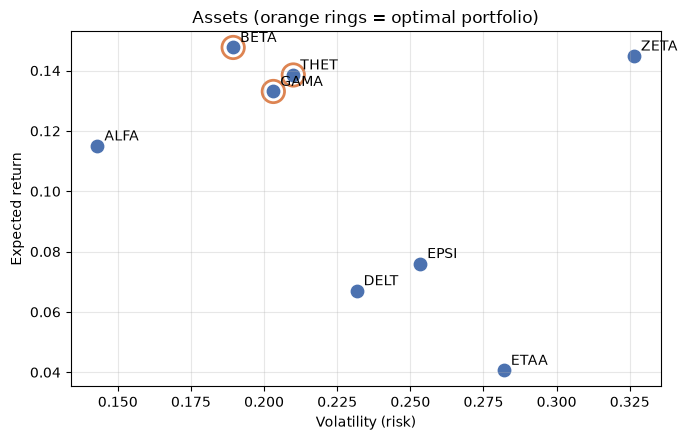

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(np.sqrt(np.diag(Sigma)), mu, s=80, color="#4c72b0")
for i, t in enumerate(tickers):
    ax.annotate(t, (np.sqrt(Sigma[i, i]), mu[i]), xytext=(5, 4), textcoords="offset points")
    if X[opt, i]:
        ax.scatter(np.sqrt(Sigma[i, i]), mu[i], s=260, facecolors="none", edgecolors="#dd8452", linewidths=2)
ax.set_xlabel("Volatility (risk)"); ax.set_ylabel("Expected return")
ax.set_title("Assets (orange rings = optimal portfolio)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig("figures/assets.png", dpi=150); plt.show()

## 3. Encoding: constraint → penalty → Hamiltonian

QAOA only minimizes a Hamiltonian; it has no notion of constraints. So we fold the budget into the cost as a **penalty**:

$$
C_\lambda(\vec{x}) = f(\vec{x}) + \lambda \Big(\sum_i x_i - K\Big)^2 .
$$

Any portfolio with the wrong number of assets pays $\lambda \times (\text{violation})^2$. Expanding everything gives a **QUBO** (quadratic unconstrained binary optimization) $\;C = \vec{x}^T Q \vec{x} + \vec{c}^{\,T}\vec{x} + \text{const}$ with

$$
Q = q\Sigma + \lambda\,\mathbf{1}\mathbf{1}^T, \qquad \vec{c} = -\vec{\mu} - 2\lambda K\,\mathbf{1}, \qquad \text{const} = \lambda K^2 .
$$

Then substitute $x_i = (1 - Z_i)/2$ (just like Max-Cut) to get Pauli $Z_i$ and $Z_iZ_j$ terms.

**Compared with Max-Cut:** the Hamiltonian now has single-qubit $Z_i$ terms (from returns and the penalty) and a $Z_iZ_j$ term for **every pair** of assets (the penalty couples everything to everything).

In [6]:
def qubo_to_ising(Q, c, const):
    # Convert  x^T Q x + c^T x + const  (x in {0,1}, Q symmetric)  into a SparsePauliOp.
    n = len(c)
    terms, offset = [], const
    for i in range(n):
        # x_i -> (1 - Z_i)/2 ;  x_i x_j -> (1 - Z_i - Z_j + Z_i Z_j)/4
        h_i = -(Q[i, i] + c[i]) / 2 - sum(Q[i, j] for j in range(n) if j != i) / 2
        terms.append(("Z", [i], h_i))
        offset += (Q[i, i] + c[i]) / 2
        for j in range(i + 1, n):
            terms.append(("ZZ", [i, j], Q[i, j] / 2))
            offset += Q[i, j] / 2
    terms.append(("", [], offset))   # identity term (constant energy shift)
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()


def portfolio_problem(lam):
    # Return (Hamiltonian, cost of every basis state) for penalty strength lam.
    Q = q * Sigma + lam * np.ones((n, n))
    c = -mu - 2 * lam * K * np.ones(n)
    H = qubo_to_ising(Q, c, lam * K**2)
    costs = f + lam * (n_picked - K) ** 2
    return H, costs


H, costs = portfolio_problem(lam=0.1)
print(f"Hamiltonian has {len(H)} Pauli terms on {H.num_qubits} qubits")
print(H[:5], "...")

# Sanity check: the Hamiltonian's diagonal must equal the penalized cost of every portfolio
diag = np.real(H.to_matrix(sparse=True).diagonal())
print("\nHamiltonian matches brute-force cost for all 256 portfolios:", np.allclose(diag, costs))

Hamiltonian has 37 Pauli terms on 8 qubits
SparsePauliOp(['IIIIIIIZ', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIZIIIZ'],
              coeffs=[-0.0803382 +0.j,  0.04666969+0.j,  0.05378321+0.j,  0.04699745+0.j,
  0.05680811+0.j]) ...

Hamiltonian matches brute-force cost for all 256 portfolios: True


### How big should the penalty be?

There is an exact threshold. The penalty is only "strong enough" when the **lowest-energy state is a valid portfolio**. That happens iff, for every invalid portfolio $x$,
$f(x) + \lambda(|x|-K)^2 \ge f_{\text{opt}}$, i.e.

$$
\lambda \;\ge\; \lambda_{\text{crit}} = \max_{x\ \text{invalid}} \frac{f_{\text{opt}} - f(x)}{(|x|-K)^2}.
$$

Below $\lambda_{\text{crit}}$ even a *perfect* solver returns an invalid portfolio. Far above it, the penalty dominates the energy landscape and drowns out the return/risk differences QAOA needs to see. We'll measure $\lambda$ in units of $\lambda_{\text{crit}}$.

In [7]:
inv = ~valid
lam_crit = max(0.0, np.max((f_opt - f[inv]) / (n_picked[inv] - K) ** 2))
print(f"lambda_crit = {lam_crit:.4f}")

# Check: just below / just above the threshold
for factor in [0.9, 1.1]:
    _, cst = portfolio_problem(factor * lam_crit)
    gs = int(np.argmin(cst))
    print(f"lambda = {factor} x crit -> ground state picks {n_picked[gs]} assets ({'valid' if valid[gs] else 'INVALID'})")

lambda_crit = 0.0796
lambda = 0.9 x crit -> ground state picks 4 assets (INVALID)
lambda = 1.1 x crit -> ground state picks 3 assets (valid)


## 4. The QAOA circuit (Qiskit)

Exactly as in the tutorial: `QAOAAnsatz` builds $|+\rangle^{\otimes n}$ followed by $p$ rounds of cost layer $e^{-i\gamma_k H_C}$ and mixer $e^{-i\beta_k \sum_i X_i}$.

Two practical details:
- We **rescale** $H$ so its largest coefficient is 1. This keeps good $\gamma$ values in a similar range whatever $\lambda$ is, which makes optimization much easier.
- Qiskit orders the parameters **alphabetically**: $[\beta_0,\dots,\beta_{p-1},\gamma_0,\dots,\gamma_{p-1}]$. We follow that order everywhere.

Parameter order: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]
Circuit depth after decomposition: 43


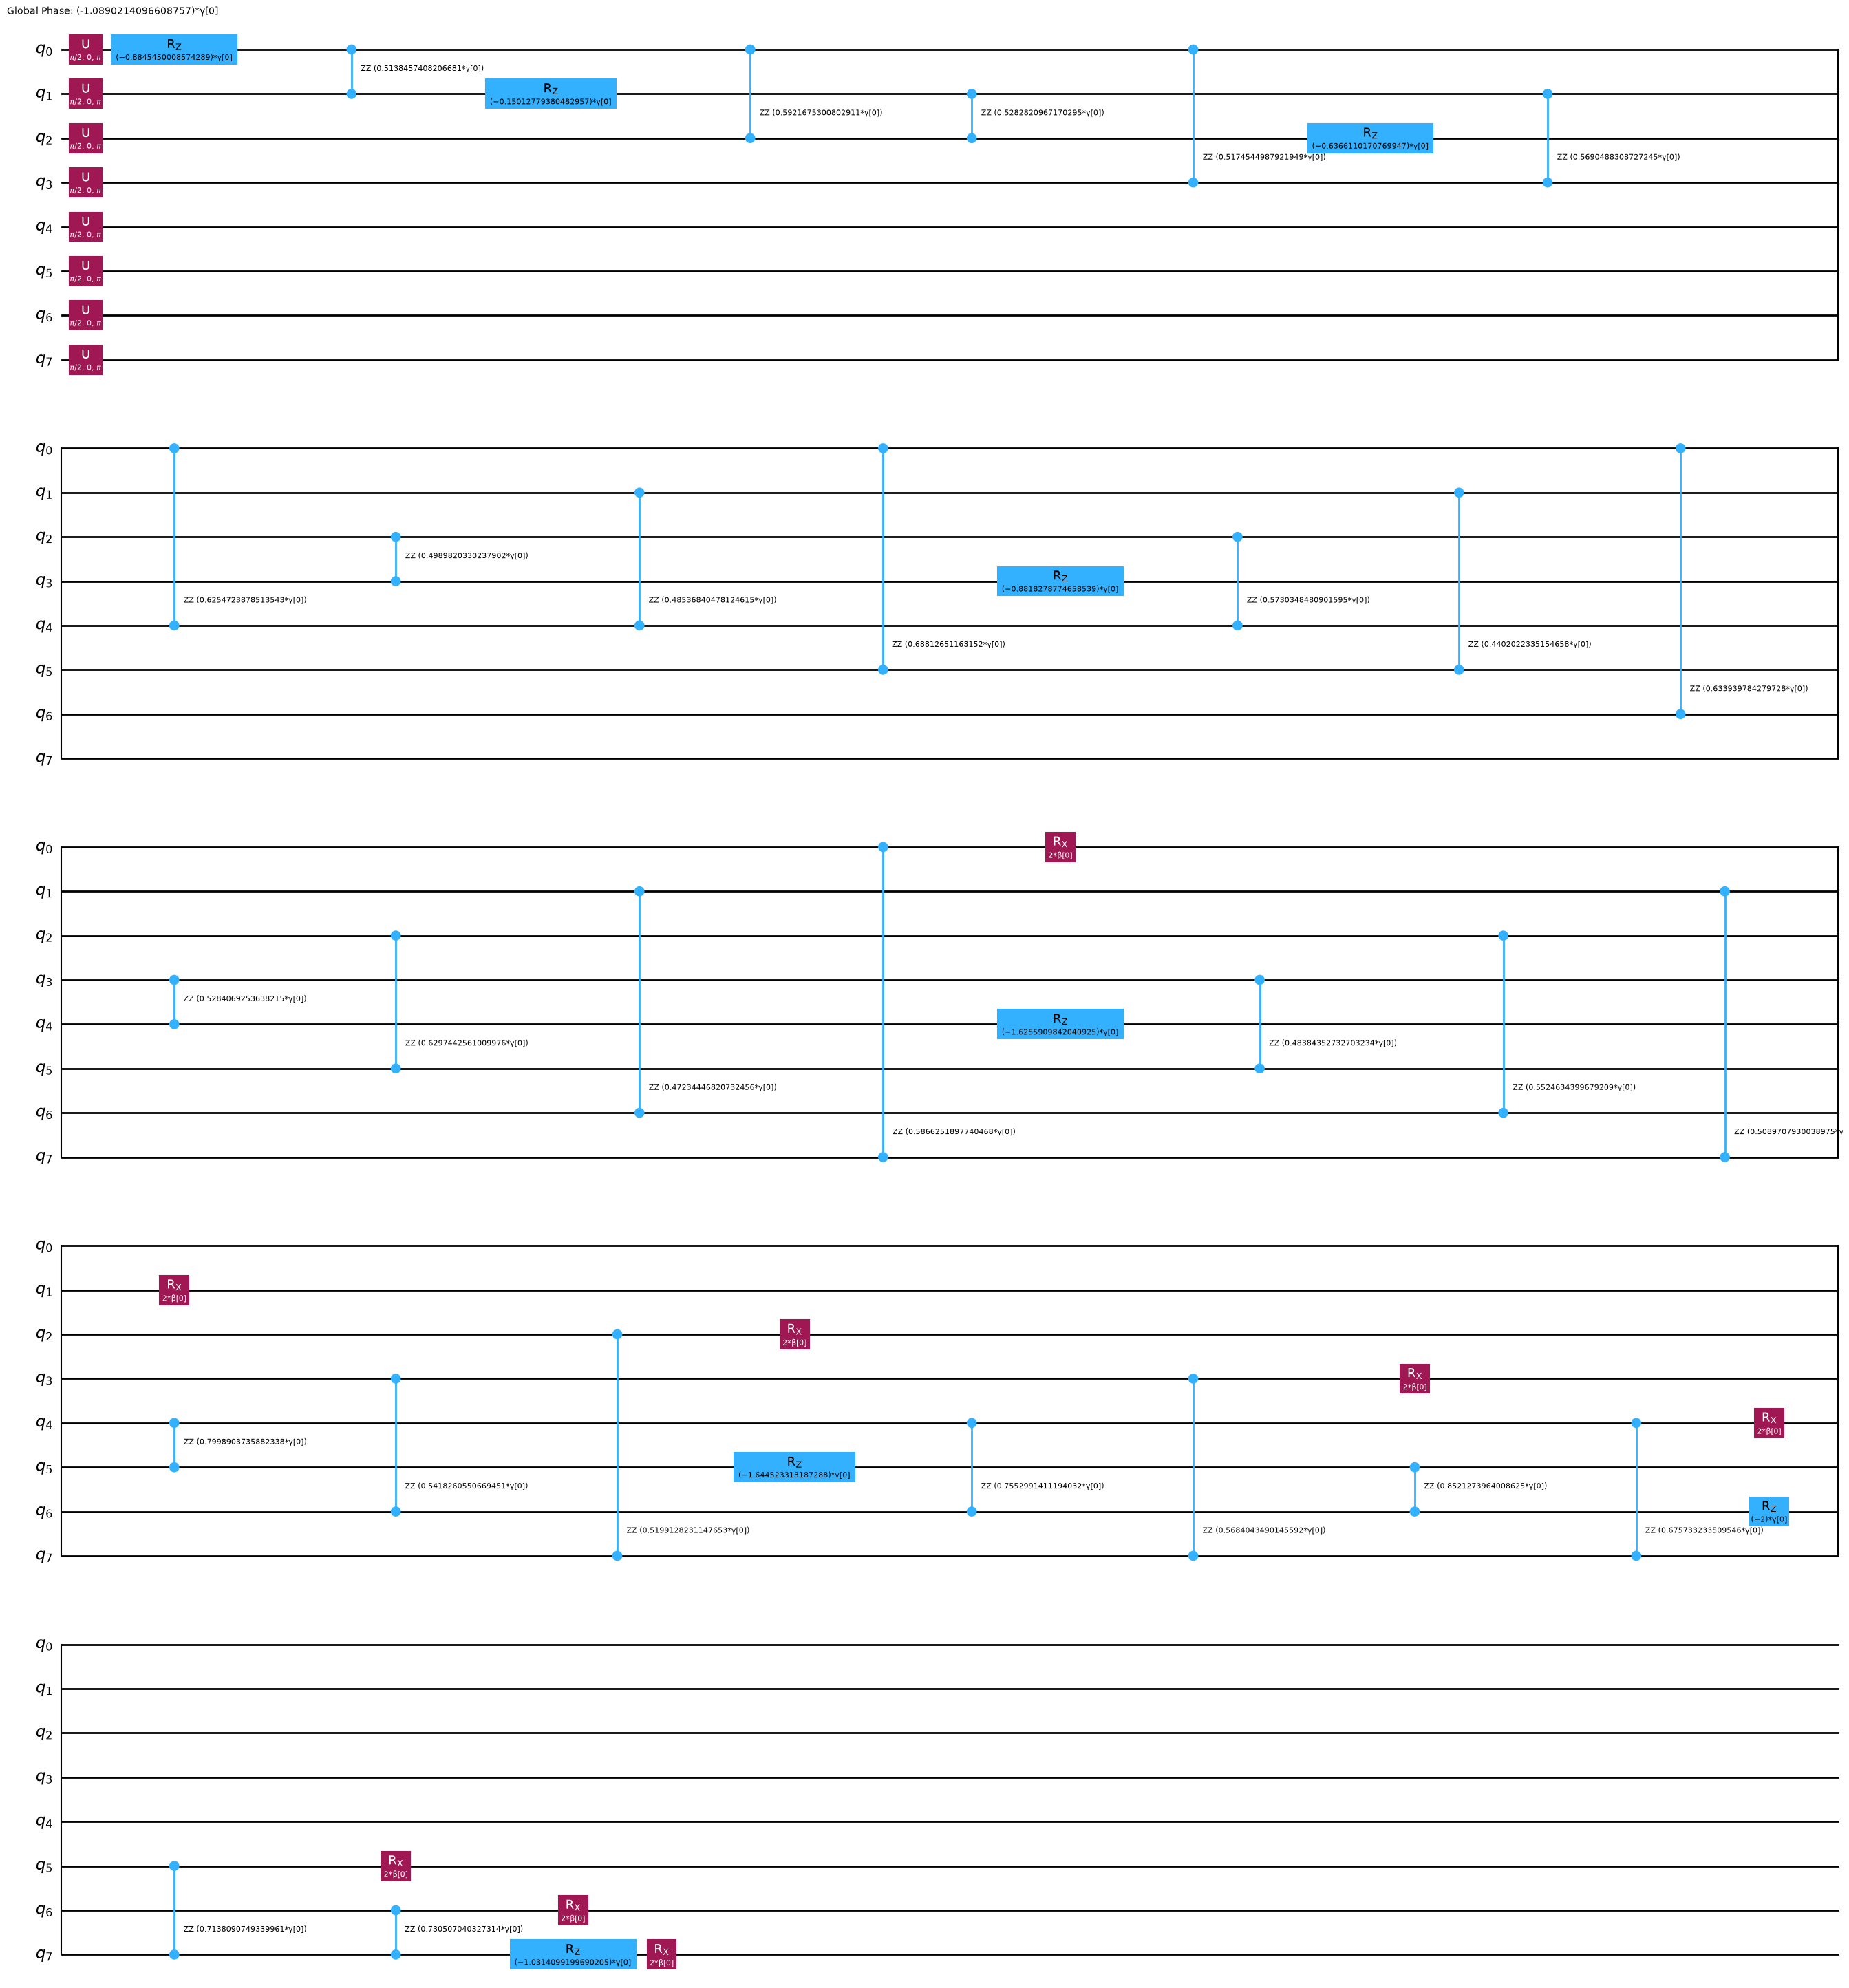

In [8]:
def scale_of(H):
    # Largest |coefficient| among the non-identity terms
    labels = H.paulis.to_labels()
    return np.max(np.abs(H.coeffs[[l != "I" * H.num_qubits for l in labels]]))

p_demo = 1
ansatz_demo = QAOAAnsatz(cost_operator=(H / scale_of(H)).simplify(), reps=p_demo)
print("Parameter order:", list(ansatz_demo.parameters))
print("Circuit depth after decomposition:", ansatz_demo.decompose(reps=3).depth())
try:
    display(ansatz_demo.decompose(reps=2).draw("mpl", fold=40))
except Exception:   # 'mpl' drawing needs `pip install pylatexenc`; fall back to text
    print(ansatz_demo.decompose(reps=2).draw("text", fold=120))

## 5. A fast exact simulator (verified against Qiskit)

To *study* $\lambda$ and $p$ we need thousands of circuit evaluations. Rebinding and simulating the Qiskit circuit costs ~0.3 s per call; that's hours for a sweep.

Because the cost Hamiltonian is **diagonal**, the QAOA state is cheap to compute directly:
- cost layer = multiply each amplitude by $e^{-i\gamma\, C(b)}$,
- mixer layer = apply $R_X(2\beta)$ to every qubit.

We verify it reproduces Qiskit's statevector to machine precision, then use it for the sweeps. The final showcase in Section 8 uses the real Qiskit circuit and sampler.

In [9]:
def qaoa_probs(costs_scaled, betas, gammas):
    # Exact QAOA output distribution for the standard X mixer.
    n = int(np.log2(len(costs_scaled)))
    psi = np.full(2**n, 2 ** (-n / 2), dtype=complex)            # |+>^n
    for b, g in zip(betas, gammas):
        psi = psi * np.exp(-1j * g * costs_scaled)               # cost layer (diagonal)
        rx = np.array([[np.cos(b), -1j * np.sin(b)],
                       [-1j * np.sin(b), np.cos(b)]])            # exp(-i b X)
        t = psi.reshape([2] * n)
        for ax in range(n):                                      # mixer on every qubit
            t = np.moveaxis(np.tensordot(rx, t, axes=([1], [ax])), 0, ax)
        psi = t.reshape(-1)
    return np.abs(psi) ** 2


# --- Verification against Qiskit ---
s = scale_of(H)
test_params = np.random.default_rng(0).uniform(0, np.pi, 2 * p_demo)   # [betas..., gammas...]
t0 = time.time()
p_qiskit = Statevector(ansatz_demo.assign_parameters(test_params)).probabilities()
t_qiskit = time.time() - t0
t0 = time.time()
p_fast = qaoa_probs(costs / s, test_params[:p_demo], test_params[p_demo:])
t_fast = time.time() - t0
print(f"Max difference vs Qiskit: {np.abs(p_qiskit - p_fast).max():.1e}")
print(f"Qiskit: {t_qiskit*1e3:.1f} ms   fast sim: {t_fast*1e3:.2f} ms   (~{t_qiskit/t_fast:.0f}x faster)")

Max difference vs Qiskit: 7.4e-16
Qiskit: 579.5 ms   fast sim: 0.41 ms   (~1431x faster)


## 6. Optimizing the angles

Same hybrid loop as the tutorial: COBYLA minimizes the expected cost $\langle C_\lambda \rangle$. QAOA is sensitive to initialization, so for each depth we try several starting points and keep the best:
- **Linear ramp**: $\gamma$ grows and $\beta$ shrinks across layers (mimics a slow "annealing" schedule, a well-known good default).
- **INTERP** (Zhou et al., 2020): reuse the optimal angles from depth $p$, interpolated onto $p+1$ layers. This means deeper circuits start from where shallower ones left off.
- A few **random** starts.

In [10]:
def metrics(probs):
    p_valid = probs[valid].sum()
    p_opt = probs[opt]
    if p_valid > 0:
        mean_f_valid = probs[valid] @ f[valid] / p_valid
        quality = (f_worst - mean_f_valid) / (f_worst - f_opt)
    else:
        quality = np.nan
    return dict(p_valid=p_valid, p_opt=p_opt, quality=quality)


def ramp_init(p, delta=0.8):
    t = (np.arange(p) + 0.5) / p
    return np.concatenate([(1 - t) * delta, t * delta])          # [betas, gammas]


def interp_init(prev, p_prev):
    # INTERP: angles for depth p_prev -> starting angles for depth p_prev + 1
    def grow(v):
        v = np.concatenate([[0.0], v, [0.0]])
        p = p_prev
        return np.array([(i / p) * v[i] + ((p - i) / p) * v[i + 1] for i in range(p + 1)])
    return np.concatenate([grow(prev[:p_prev]), grow(prev[p_prev:])])


def optimize_qaoa(costs, p, prev_params=None, n_random=2, seed=0, maxiter=None,
                  sim=None, scale=None, objective=None):
    # sim: simulator (default: standard X-mixer QAOA); objective: function of probs (default: mean cost)
    sim = sim or qaoa_probs
    objective = objective or (lambda probs: probs @ costs)
    s = scale or np.max(np.abs(costs - costs.mean())) or 1.0    # normalise the energy scale
    cs = costs / s
    energy = lambda x: objective(sim(cs, x[:p], x[p:]))
    starts = [ramp_init(p)]
    if prev_params is not None:
        starts.append(interp_init(prev_params, p - 1))
    r = np.random.default_rng(seed)
    starts += [r.uniform(0, np.pi, 2 * p) for _ in range(n_random)]
    best = None
    for x0 in starts:
        res = minimize(energy, x0, method="COBYLA", options={"maxiter": maxiter or 250 * p})
        if best is None or res.fun < best.fun:
            best = res
    probs = sim(cs, best.x[:p], best.x[p:])
    return best.x, probs, s

## 7. Experiments: penalty $\lambda$ × depth $p$

> **Note on scaling.** Inside `optimize_qaoa` we divide the cost by its spread, not by the largest Pauli coefficient as in Section 4. Both are just a choice of units for $\gamma$; this one is simpler because it works directly on the cost vector. The circuit in Section 8 uses the same scale `s`, so the angles transfer exactly.

For each penalty strength we run depths $p = 1 \dots 5$ (each depth warm-started from the previous one with INTERP). This single grid answers both beginner questions. It takes about a minute.

In [11]:
lam_factors = [0.0, 0.5, 1.0, 2.0, 5.0, 10.0, 30.0] 
depths = [1, 2, 3, 4, 5]

results = {}   # (lam_factor, p) -> dict(metrics, params, scale)
t_start = time.time()
for lf in lam_factors:
    _, cst = portfolio_problem(lf * lam_crit)
    prev = None
    for p in depths:
        params, probs, s = optimize_qaoa(cst, p, prev_params=prev, seed=p)
        results[(lf, p)] = dict(**metrics(probs), params=params, scale=s)
        prev = params
    row = "  ".join(f"p{p}: {results[(lf, p)]['p_valid']:.2f}/{results[(lf, p)]['p_opt']:.3f}" for p in depths)
    print(f"lambda = {lf:>4} x crit   [P(valid)/P(opt)]  {row}")
print(f"\nDone in {time.time() - t_start:.0f} s")

# Save raw numbers for the presentation
with open("results/sweep.csv", "w") as fh:
    fh.write("lam_factor,lam,p,p_valid,p_opt,quality\n")
    for (lf, p), r in results.items():
        fh.write(f"{lf},{lf*lam_crit},{p},{r['p_valid']},{r['p_opt']},{r['quality']}\n")

lambda =  0.0 x crit   [P(valid)/P(opt)]  p1: 0.19/0.029  p2: 0.07/0.019  p3: 0.02/0.004  p4: 0.00/0.000  p5: 0.00/0.000
lambda =  0.5 x crit   [P(valid)/P(opt)]  p1: 0.43/0.019  p2: 0.40/0.065  p3: 0.31/0.081  p4: 0.21/0.070  p5: 0.17/0.071
lambda =  1.0 x crit   [P(valid)/P(opt)]  p1: 0.48/0.013  p2: 0.61/0.029  p3: 0.53/0.033  p4: 0.53/0.030  p5: 0.62/0.060
lambda =  2.0 x crit   [P(valid)/P(opt)]  p1: 0.50/0.011  p2: 0.57/0.015  p3: 0.62/0.017  p4: 0.64/0.018  p5: 0.65/0.023
lambda =  5.0 x crit   [P(valid)/P(opt)]  p1: 0.49/0.010  p2: 0.61/0.013  p3: 0.68/0.015  p4: 0.69/0.015  p5: 0.70/0.015
lambda = 10.0 x crit   [P(valid)/P(opt)]  p1: 0.50/0.009  p2: 0.61/0.012  p3: 0.71/0.014  p4: 0.79/0.016  p5: 0.88/0.018
lambda = 30.0 x crit   [P(valid)/P(opt)]  p1: 0.50/0.009  p2: 0.61/0.011  p3: 0.70/0.013  p4: 0.79/0.015  p5: 0.87/0.016

Done in 177 s


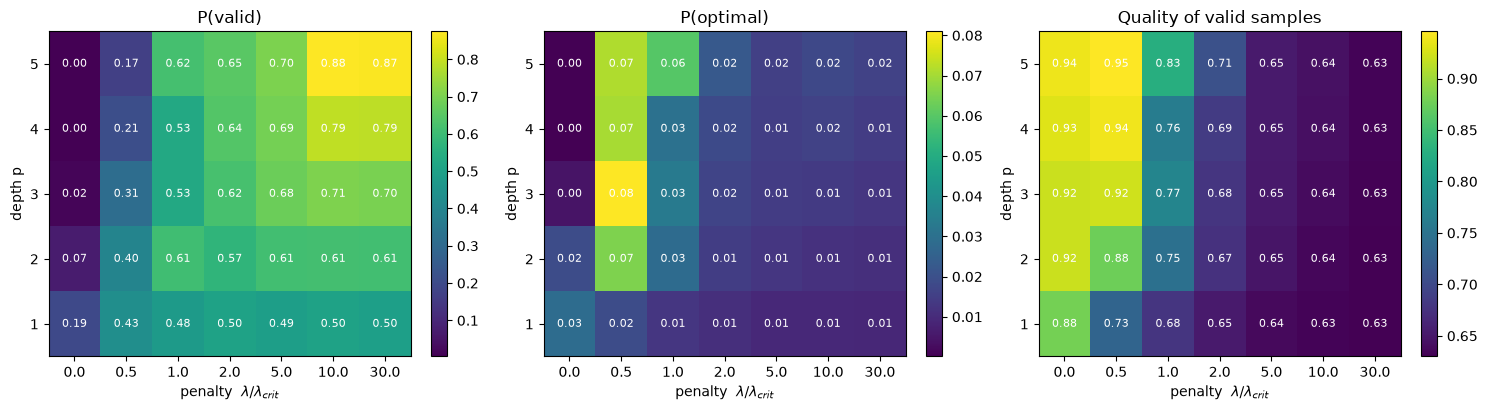

Random-guess baselines:  P(valid) = 0.22   P(optimal) = 0.0039   quality = 0.63


In [12]:
def grid(key):
    return np.array([[results[(lf, p)][key] for lf in lam_factors] for p in depths])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key, title in zip(axes, ["p_valid", "p_opt", "quality"],
                          ["P(valid)", "P(optimal)", "Quality of valid samples"]):
    G = grid(key)
    im = ax.imshow(G, origin="lower", aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(lam_factors)), [str(x) for x in lam_factors])
    ax.set_yticks(range(len(depths)), depths)
    ax.set_xlabel(r"penalty  $\lambda / \lambda_{crit}$"); ax.set_ylabel("depth p")
    ax.set_title(title)
    for i in range(len(depths)):
        for j in range(len(lam_factors)):
            ax.text(j, i, f"{G[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig("figures/heatmaps.png", dpi=150); plt.show()

print(f"Random-guess baselines:  P(valid) = {valid.mean():.2f}   P(optimal) = {1/2**n:.4f}   "
      f"quality = {(f_worst - f[valid].mean()) / (f_worst - f_opt):.2f}")

## 8. Showcase: the real Qiskit circuit, sampled

Take the best configuration from the grid, build the actual `QAOAAnsatz` circuit with the optimized angles, and sample it with Qiskit's `StatevectorSampler` (4096 shots), exactly as you would on a backend.

In [13]:
# Best setting among penalties that make the true optimum the ground state (lambda >= lambda_crit)
best_key = max((k for k in results if k[0] >= 1.0), key=lambda k: results[k]["p_opt"])
lf_best, p_best = best_key
r = results[best_key]
H_best, cost_best = portfolio_problem(lf_best * lam_crit)

# Build the Qiskit circuit with the SAME scaling used during optimisation
H_shift = (H_best - SparsePauliOp("I" * n, cost_best.mean())).simplify()   # remove mean (global phase only)
ansatz = QAOAAnsatz(cost_operator=(H_shift / r["scale"]).simplify(), reps=p_best)
ansatz.measure_all()
bound = ansatz.assign_parameters(r["params"])

shots = 4096
counts = StatevectorSampler(seed=SEED).run([bound], shots=shots).result()[0].data.meas.get_counts()

def key_to_index(key):
    return int(key, 2)   # Qiskit bitstrings are little-endian, so int(key, 2) is our basis index b

sampled = np.zeros(2**n)
for k, v in counts.items():
    sampled[key_to_index(k)] += v / shots

print(f"Best setting: lambda = {lf_best} x crit, p = {p_best}")
print(f"Sampled  P(valid) = {sampled[valid].sum():.3f}   P(optimal) = {sampled[opt]:.3f}")
print(f"Predicted P(valid) = {r['p_valid']:.3f}   P(optimal) = {r['p_opt']:.3f}   (fast simulator)")

rank = {b: i + 1 for i, b in enumerate(np.argsort(np.where(valid, f, np.inf))[: valid.sum()])}
print("\nMost frequent portfolios:")
for b in np.argsort(-sampled)[:8]:
    tag = f"valid, rank {rank[b]:>2}/{valid.sum()}" if valid[b] else f"INVALID ({n_picked[b]} assets)"
    print(f"  {sampled[b]:6.1%}  {str(names(b)):32s} {tag}")

Best setting: lambda = 1.0 x crit, p = 5
Sampled  P(valid) = 0.621   P(optimal) = 0.061
Predicted P(valid) = 0.619   P(optimal) = 0.060   (fast simulator)

Most frequent portfolios:
    6.2%  ['ALFA', 'BETA', 'GAMA']         valid, rank  3/56
    6.1%  ['BETA', 'GAMA', 'THET']         valid, rank  1/56
    4.5%  ['ALFA', 'BETA', 'THET']         valid, rank  2/56
    4.5%  ['BETA', 'GAMA', 'DELT']         valid, rank 10/56
    3.4%  ['ALFA', 'BETA', 'DELT']         valid, rank  9/56
    2.7%  ['ALFA', 'BETA', 'GAMA', 'THET'] INVALID (4 assets)
    2.7%  ['ALFA', 'BETA', 'GAMA', 'DELT'] INVALID (4 assets)
    2.4%  ['BETA', 'DELT', 'THET']         valid, rank 13/56


## 9. Takeaways (Beginner) and the road to Intermediate

**What the beginner level shows** *(numbers from the seeded run; small differences on another machine are normal)*
1. **The encoding is exact:** the Hamiltonian reproduces the penalized cost of all 256 portfolios, and the Qiskit sampler agrees with the fast simulator.
2. **No penalty, no constraint:** at $\lambda = 0$, deeper QAOA pushes P(valid) to **0**. It correctly finds the *unconstrained* optimum, which buys more than 3 assets.
3. **The penalty creates a trade-off, not a fix.** Increasing $\lambda$ raises P(valid) (≈0.5 → 0.9), but the *quality* of the valid portfolios falls to the **random-guess level (≈0.63)**. A large penalty dominates the energy landscape and drowns out the return/risk signal.
4. **The sweet spot is narrow:** $\lambda \approx \lambda_{\text{crit}}$ gives the best P(optimal) among valid formulations, improving with depth ($p=1 \to 5$: ≈1% → ≈6%, about 15× random), yet **≈40% of the probability is still wasted on invalid portfolios.**
5. **Depth costs a lot:** every layer adds 28 all-to-all $ZZ$ gates and 2 parameters, and the optimizer needs INTERP and restarts to make progress.

**One-line summary:** *penalties make QAOA trade feasibility against quality. To get both, the constraint has to be built into the circuit.*

**→ Intermediate (improved-QAOA route): make invalid portfolios impossible**

Instead of penalizing invalid portfolios, never create them:
- **Initial state:** a *Dicke state* $|D^n_K\rangle$, an equal superposition of all portfolios with exactly $K$ assets (instead of $|+\rangle^{\otimes n}$).
- **Mixer:** an *XY mixer* $\sum_{i} (X_iX_{i+1} + Y_iY_{i+1})$, which swaps "in" and "out" between assets but **preserves the number of 1s**.
- **Cost:** just $f(\vec{x})$, **with no penalty and no $\lambda$ to tune**.

Then P(valid) = 1 by construction, and all the circuit's effort goes into finding the best valid portfolio. Compare it directly against the heatmaps above. Bonus: optimize **CVaR** (the mean of the best α% of samples) instead of the plain average.

`QAOAAnsatz` already accepts `initial_state=` and `mixer_operator=`, so the code structure here carries over.

---
# Intermediate: Constraint-Preserving QAOA (XY mixer)

**Route chosen: improved QAOA.** The beginner results show that the penalty forces a trade-off between *valid* and *good*. The fix is to stop *penalizing* invalid portfolios and make them **impossible**: the circuit should never leave the set of portfolios with exactly $K$ assets.

Two changes to the QAOA recipe (Hadfield et al., *"From the QAOA to the Quantum Alternating Operator Ansatz"*, 2019):

| | Beginner (penalty QAOA) | Intermediate (XY-QAOA) |
|---|---|---|
| Initial state | $\lvert + \rangle^{\otimes n}$: all 256 portfolios | **Dicke state** $\lvert D^n_K\rangle$: equal superposition of the 56 valid portfolios |
| Mixer | $\sum_i X_i$: flips assets in/out, **changes** the count | **XY mixer** $\sum_{\langle i,j\rangle} \tfrac12(X_iX_j + Y_iY_j)$: **swaps** an asset in for an asset out, **preserves** the count |
| Cost | $f(\vec x) + \lambda(\sum x_i - K)^2$ | just $f(\vec x)$: **no penalty, no $\lambda$ to tune** |

The XY term acts as $\lvert 01\rangle \leftrightarrow \lvert 10\rangle$ and leaves $\lvert 00\rangle, \lvert 11\rangle$ alone, so the number of 1s (assets held) can never change. The cost layer is diagonal and also preserves it. Therefore **P(valid) = 1 by construction**, and every bit of optimization effort goes into *quality*.

## 10. The Dicke state

We prepare $\lvert D^n_K\rangle$ with the deterministic circuit of **Bärtschi & Eidenbenz (2019)**: start from $K$ ones, then apply "split & cyclic shift" blocks built from controlled-$R_Y$ rotations that spread the ones evenly over all positions. It uses $O(nK)$ gates, which is far cheaper than generic state preparation.

In [14]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import RYGate, XXPlusYYGate


def dicke_state(n, k):
    # Bärtschi & Eidenbenz (2019): |0...0 1...1> -> |D^n_k>, via Split-&-Cyclic-Shift (SCS) blocks.
    qc = QuantumCircuit(n, name=f"Dicke({n},{k})")
    qc.x(range(n - k, n))                                   # k ones on the top qubits

    def scs(m, kk):                                         # SCS_{m,kk} on qubits 0..m-1
        top = m - 1
        qc.cx(top - 1, top)
        qc.cry(2 * np.arccos(np.sqrt(1 / m)), top, top - 1)
        qc.cx(top - 1, top)
        for l in range(2, kk + 1):
            a = top - l
            qc.cx(a, top)
            qc.append(RYGate(2 * np.arccos(np.sqrt(l / m))).control(2), [top, a + 1, a])
            qc.cx(a, top)

    for m in range(n, k, -1):
        scs(m, k)
    for m in range(k, 1, -1):
        scs(m, m - 1)
    return qc


dicke = dicke_state(n, K)
target = np.where(valid, 1 / np.sqrt(valid.sum()), 0)
fid = abs(np.vdot(target, Statevector(dicke).data)) ** 2
print(f"Fidelity with the ideal Dicke state |D^{n}_{K}>: {fid:.10f}")
print(f"Probability on valid portfolios: {Statevector(dicke).probabilities()[valid].sum():.6f}")
print("CX gates:", transpile(dicke, basis_gates=["cx", "u"], optimization_level=1).count_ops().get("cx"))

Fidelity with the ideal Dicke state |D^8_3>: 1.0000000000
Probability on valid portfolios: 1.000000
CX gates: 138


## 11. The XY mixer and the full circuit

We apply $e^{-i\beta(X_iX_j + Y_iY_j)/2}$ on a **ring** of neighbouring pairs $(0,1), (1,2), \dots, (7,0)$, using Qiskit's `XXPlusYYGate`. We build the mixer as an explicit circuit and pass it to `QAOAAnsatz` through `mixer_operator=`, together with `initial_state=`. That way the gate order is fixed, which matters because neighbouring XY terms don't commute.

Parameters: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]


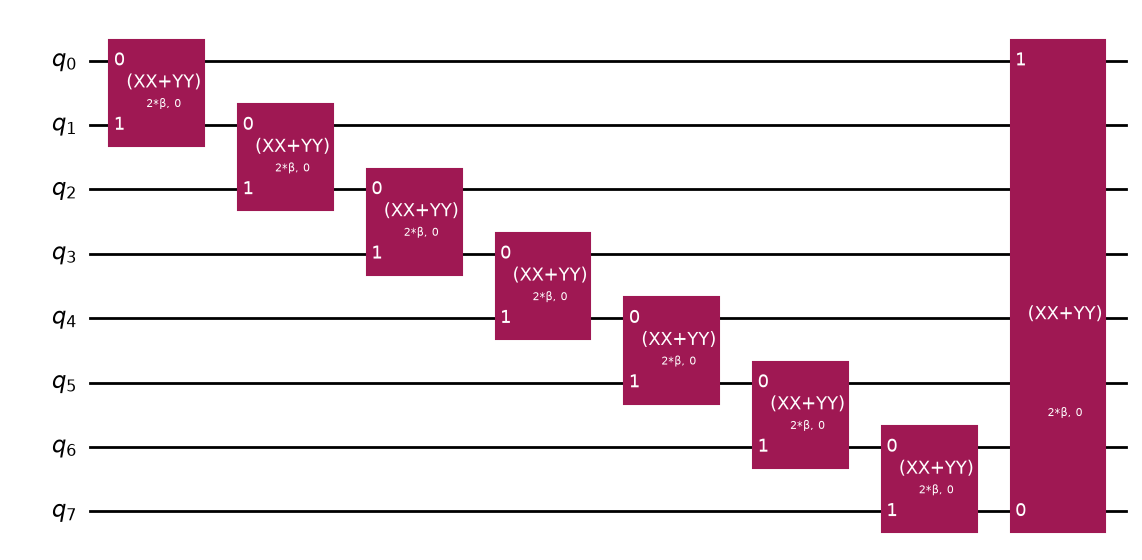

In [15]:
ring = [(i, (i + 1) % n) for i in range(n)]


def xy_mixer(n, pairs):
    beta = Parameter("β")
    qc = QuantumCircuit(n, name="XY mixer")
    for i, j in pairs:
        qc.append(XXPlusYYGate(2 * beta), [i, j])   # = exp(-i beta (XX+YY)/2)
    return qc


H_f, f_costs = portfolio_problem(lam=0.0)   # cost = f only, no penalty!
ansatz_xy_demo = QAOAAnsatz(cost_operator=H_f, reps=1,
                            initial_state=dicke, mixer_operator=xy_mixer(n, ring))
print("Parameters:", list(ansatz_xy_demo.parameters))
try:
    display(xy_mixer(n, ring).draw("mpl"))
except Exception:
    print(xy_mixer(n, ring).draw("text"))

### Fast simulator for the XY mixer (again verified against Qiskit)

Each XY gate mixes the amplitudes of portfolio $b$ and the portfolio with assets $i$ and $j$ swapped: $\psi_b \to \cos\beta\,\psi_b - i\sin\beta\,\psi_{b'}$ whenever exactly one of $i, j$ is held.

In [16]:
def qaoa_probs_xy(costs_scaled, betas, gammas, pairs=ring):
    # Exact output distribution of XY-QAOA starting from the Dicke state.
    psi = np.where(valid, 1 / np.sqrt(valid.sum()), 0).astype(complex)   # |D^n_K>
    for b, g in zip(betas, gammas):
        psi = psi * np.exp(-1j * g * costs_scaled)                       # cost layer
        for i, j in pairs:                                               # XY mixer
            swap = ((idx >> i) & 1) != ((idx >> j) & 1)
            partner = idx ^ ((1 << i) | (1 << j))
            new = psi.copy()
            new[swap] = np.cos(b) * psi[swap] - 1j * np.sin(b) * psi[partner[swap]]
            psi = new
    return np.abs(psi) ** 2


# --- Verification against the Qiskit circuit ---
p_chk = 2
ans_chk = QAOAAnsatz(cost_operator=H_f, reps=p_chk, initial_state=dicke, mixer_operator=xy_mixer(n, ring))
x_chk = np.random.default_rng(1).uniform(0, np.pi, 2 * p_chk)
p_qk = Statevector(ans_chk.assign_parameters(x_chk)).probabilities()
p_fs = qaoa_probs_xy(f_costs, x_chk[:p_chk], x_chk[p_chk:])
print(f"Max difference vs Qiskit: {np.abs(p_qk - p_fs).max():.1e}")
print(f"Probability on valid portfolios (random angles!): {p_qk[valid].sum():.6f}")

Max difference vs Qiskit: 2.8e-17
Probability on valid portfolios (random angles!): 1.000000


## 12. Optimizing XY-QAOA

Same optimizer machinery as before (linear ramp + INTERP + random restarts). We only swap in the XY simulator and optimize $\langle f \rangle$ directly. The energy is scaled by the spread of $f$ over **valid** portfolios, since those are the only ones the circuit can reach.

In [17]:
s_xy = np.max(np.abs(f[valid] - f[valid].mean()))
results_xy = {}
prev = None
t_start = time.time()
for p in depths:
    params, probs, s = optimize_qaoa(f_costs, p, prev_params=prev, seed=p, sim=qaoa_probs_xy, scale=s_xy)
    results_xy[p] = dict(**metrics(probs), params=params, scale=s)
    prev = params
    r = results_xy[p]
    print(f"p = {p}:  P(valid) = {r['p_valid']:.3f}   P(optimal) = {r['p_opt']:.3f}   quality = {r['quality']:.3f}")
print(f"Done in {time.time() - t_start:.0f} s")

p = 1:  P(valid) = 1.000   P(optimal) = 0.056   quality = 0.770
p = 2:  P(valid) = 1.000   P(optimal) = 0.084   quality = 0.811
p = 3:  P(valid) = 1.000   P(optimal) = 0.100   quality = 0.834
p = 4:  P(valid) = 1.000   P(optimal) = 0.086   quality = 0.843
p = 5:  P(valid) = 1.000   P(optimal) = 0.130   quality = 0.855
Done in 25 s


## 13. Bonus: CVaR objective

Minimizing the **average** cost rewards a state that is "decent on average". But we only *keep the best sample*, so what we really want is a state whose **best few outcomes** are excellent. **CVaR$_\alpha$** (Barkoutsos et al., *Quantum* 2020) optimizes the mean of the lowest $\alpha$ fraction of the cost distribution instead. It is a one-line change to the objective.

In [18]:
order_f = np.argsort(f_costs)   # portfolios from best to worst


def cvar(probs, alpha=0.1):
    # Mean cost of the best alpha-fraction of the distribution (exact, from probabilities)
    p_sorted = probs[order_f]
    c_sorted = f_costs[order_f]
    cum = np.cumsum(p_sorted)
    w = np.clip(alpha - (cum - p_sorted), 0, p_sorted)   # probability mass taken from each outcome
    return (w @ c_sorted) / alpha


results_cvar = {}
prev = None
for p in depths:
    params, probs, s = optimize_qaoa(f_costs, p, prev_params=prev, seed=p, sim=qaoa_probs_xy,
                                     scale=s_xy, objective=cvar)
    results_cvar[p] = dict(**metrics(probs), params=params, scale=s)
    prev = params
    r = results_cvar[p]
    print(f"p = {p}:  P(valid) = {r['p_valid']:.3f}   P(optimal) = {r['p_opt']:.3f}   quality = {r['quality']:.3f}")

p = 1:  P(valid) = 1.000   P(optimal) = 0.011   quality = 0.604
p = 2:  P(valid) = 1.000   P(optimal) = 0.085   quality = 0.642
p = 3:  P(valid) = 1.000   P(optimal) = 0.101   quality = 0.765
p = 4:  P(valid) = 1.000   P(optimal) = 0.101   quality = 0.738
p = 5:  P(valid) = 1.000   P(optimal) = 0.100   quality = 0.800


## 14. Head-to-head comparison

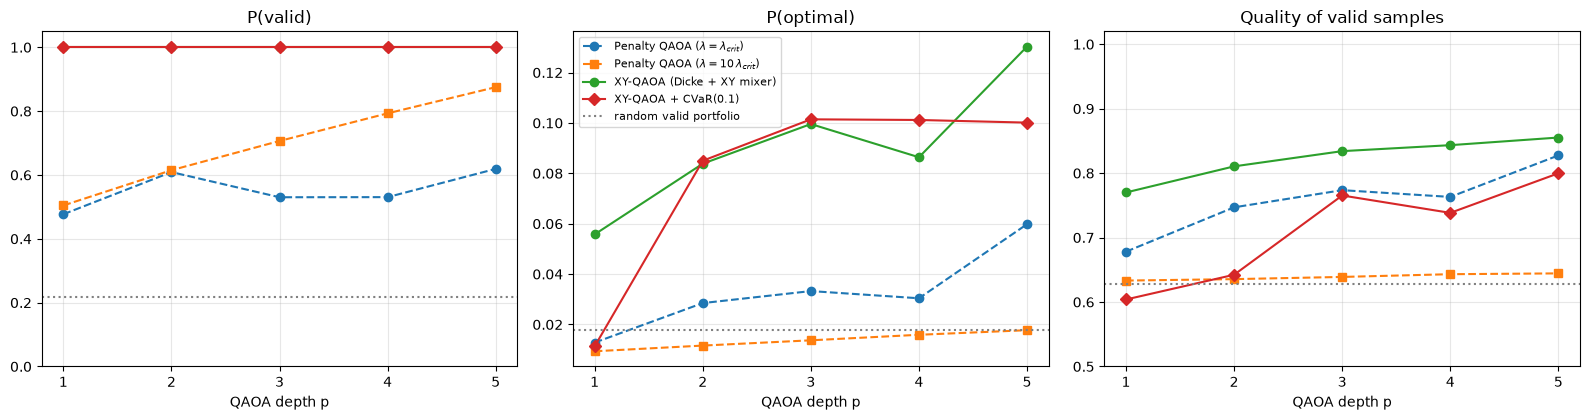

In [19]:
methods = {
    r"Penalty QAOA ($\lambda=\lambda_{crit}$)":  {p: results[(1.0, p)] for p in depths},
    r"Penalty QAOA ($\lambda=10\,\lambda_{crit}$)": {p: results[(10.0, p)] for p in depths},
    "XY-QAOA (Dicke + XY mixer)":  results_xy,
    "XY-QAOA + CVaR(0.1)":         results_cvar,
}
styles = ["o--", "s--", "o-", "D-"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for (name, res), st in zip(methods.items(), styles):
    for ax, key in zip(axes, ["p_valid", "p_opt", "quality"]):
        ax.plot(depths, [res[p][key] for p in depths], st, label=name)
# Reference: the Dicke state alone (p = 0) is a uniformly random valid portfolio
axes[0].axhline(valid.mean(), ls=":", color="gray", label="random bitstring")
axes[1].axhline(1 / valid.sum(), ls=":", color="gray", label="random valid portfolio")
axes[2].axhline((f_worst - f[valid].mean()) / (f_worst - f_opt), ls=":", color="gray", label="random valid portfolio")
for ax, title in zip(axes, ["P(valid)", "P(optimal)", "Quality of valid samples"]):
    ax.set_title(title); ax.set_xlabel("QAOA depth p"); ax.set_xticks(depths); ax.grid(alpha=0.3)
axes[0].set_ylim(0, 1.05); axes[2].set_ylim(0.5, 1.02)
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig("figures/comparison.png", dpi=150); plt.show()

### Classical baselines: how would a normal computer do?

A fair comparison needs classical methods on the **same problem**. We try three standard approaches:

1. **Exact enumeration:** score all $\binom{8}{3} = 56$ valid portfolios and take the best. Guaranteed optimal.
2. **Greedy:** add the stock that lowers the cost most, one at a time, until we hold $K$. Fast, but no guarantee.
3. **Simulated annealing (SA):** start from a random valid portfolio and repeatedly try **swapping one stock in for one out** (so it always holds exactly $K$, the classical cousin of the XY mixer). Accept worse moves with a probability that falls as the "temperature" cools, which lets it escape local minima.

To compare like with like, we treat one SA run, or one QAOA measurement shot, as a single "attempt" and ask: **how likely is one attempt to return the optimal portfolio?**

In [20]:
from itertools import combinations


def cost_of(S):
    S = list(S)
    return q * Sigma[np.ix_(S, S)].sum() - mu[S].sum()


# 1) Exact enumeration of the valid portfolios
t0 = time.perf_counter()
best_exact = min(combinations(range(n), K), key=cost_of)
t_exact = time.perf_counter() - t0

# 2) Greedy
def greedy():
    S = []
    for _ in range(K):
        S.append(min((i for i in range(n) if i not in S), key=lambda i: cost_of(S + [i])))
    return S

t0 = time.perf_counter()
best_greedy = greedy()
t_greedy = time.perf_counter() - t0

# 3) Simulated annealing with swap moves (always exactly K assets)
def anneal(seed, steps, T_start=0.05, T_end=1e-4):
    r_ = np.random.default_rng(seed)
    S = list(r_.choice(n, K, replace=False)); cur = cost_of(S)
    best_S, best_c = S[:], cur
    for t in range(steps):
        T = T_start * (T_end / T_start) ** (t / steps)
        S2 = S[:]
        S2[r_.integers(K)] = r_.choice([i for i in range(n) if i not in S])   # swap one out, one in
        c2 = cost_of(S2)
        if c2 < cur or r_.random() < np.exp((cur - c2) / T):
            S, cur = S2, c2
            if cur < best_c:
                best_S, best_c = S[:], cur
    return best_S, best_c

opt_set = set(np.flatnonzero(X[opt]))
sa_rows = []
for steps in [5, 10, 20, 50]:
    t0 = time.perf_counter()
    runs = [anneal(seed, steps) for seed in range(500)]
    dt = (time.perf_counter() - t0) / len(runs)
    hit = np.mean([set(S) == opt_set for S, _ in runs])
    sa_rows.append((steps, hit, dt))

show = lambda S: sorted(tickers[i] for i in S)
print(f"Optimal portfolio (brute force over all 256): {names(opt)}\n")
print(f"{'method':38s} {'P(optimal) per attempt':>23s} {'time per attempt':>17s}")
print(f"{'Exact enumeration (56 portfolios)':38s} {1.0:23.3f} {t_exact*1e3:14.2f} ms   -> {show(best_exact)}")
print(f"{'Greedy':38s} {float(set(best_greedy) == opt_set):23.3f} {t_greedy*1e3:14.2f} ms   -> {show(best_greedy)}")
for steps, hit, dt in sa_rows:
    print(f"{f'Simulated annealing ({steps} swap steps)':38s} {hit:23.3f} {dt*1e3:14.2f} ms")
print(f"{'Random valid portfolio':38s} {1/valid.sum():23.3f}")
print(f"{'Penalty QAOA (best, ideal), per shot':38s} {max(results[(1.0, p)]['p_opt'] for p in depths):23.3f}")
print(f"{'XY-QAOA (best, ideal), per shot':38s} {max(r['p_opt'] for r in results_xy.values()):23.3f}")

with open("results/classical_baselines.csv", "w") as fh:
    fh.write("method,p_opt_per_attempt,seconds_per_attempt\n")
    fh.write(f"exact,1.0,{t_exact}\ngreedy,{float(set(best_greedy) == opt_set)},{t_greedy}\n")
    for steps, hit, dt in sa_rows:
        fh.write(f"SA_{steps}_steps,{hit},{dt}\n")

Optimal portfolio (brute force over all 256): ['BETA', 'GAMA', 'THET']

method                                  P(optimal) per attempt  time per attempt
Exact enumeration (56 portfolios)                        1.000           2.40 ms   -> ['BETA', 'GAMA', 'THET']
Greedy                                                   1.000           0.97 ms   -> ['BETA', 'GAMA', 'THET']
Simulated annealing (5 swap steps)                       0.162           0.27 ms
Simulated annealing (10 swap steps)                      0.358           0.35 ms
Simulated annealing (20 swap steps)                      0.646           0.73 ms
Simulated annealing (50 swap steps)                      0.958           1.50 ms
Random valid portfolio                                   0.018
Penalty QAOA (best, ideal), per shot                     0.060
XY-QAOA (best, ideal), per shot                          0.130


**The honest verdict.** At 8 assets, **classical wins easily.** Exact enumeration takes a few milliseconds at most, and a few dozen annealing steps almost always find the optimum. QAOA's best per-shot success (≈13%) is far better than random (≈2%), but it is **not competitive** with a laptop, and nobody expects it to be at this size.

So why do this at all? The question this project answers is not *"is quantum faster today?"* but **"which quantum encoding of a constrained problem works best, and what limits it?"** That matters because classical exact methods hit a wall: picking 10 of 100 stocks means $\binom{100}{10} \approx 1.7\times10^{13}$ portfolios, and the constrained problem is NP-hard in general. Heuristics like annealing still work there, so they are the real benchmark any future quantum optimizer has to beat.

Interesting parallel: simulated annealing's best move is a **swap** (one stock in, one out), which keeps every candidate valid. That is exactly the idea behind the **XY mixer**. Both methods discovered that you should search *inside* the feasible set rather than penalize leaving it.

### What does it cost in gates?

A fair comparison must include circuit size. Below we compile each circuit to CX + single-qubit gates (all-to-all connectivity, as on the simulator) and count **CX gates**, the expensive, noisy operations on real hardware.

In [21]:
def cx_count(qc):
    return transpile(qc, basis_gates=["cx", "u"], optimization_level=1).count_ops().get("cx", 0)

H_pen, _ = portfolio_problem(lam_crit)
rows = []
for p in [1, max(depths)]:
    c_pen = cx_count(QAOAAnsatz(H_pen, reps=p).assign_parameters(np.full(2 * p, 0.3)))   # nonzero angles, or gates get optimised away
    c_xy = cx_count(QAOAAnsatz(H_f, reps=p, initial_state=dicke,
                               mixer_operator=xy_mixer(n, ring)).assign_parameters(np.full(2 * p, 0.3)))
    rows.append((p, c_pen, c_xy))
    print(f"p = {p}:  penalty QAOA {c_pen:4d} CX    XY-QAOA {c_xy:4d} CX")

p = 1:  penalty QAOA   56 CX    XY-QAOA  210 CX
p = 5:  penalty QAOA  280 CX    XY-QAOA  498 CX


In [22]:
# Summary table, saved for the slides
summary = []
for name, res in methods.items():
    p_star = max(depths, key=lambda p: res[p]["p_opt"])
    r = res[p_star]
    summary.append((name.replace("$", "").replace("\\", "").replace("{", "").replace("}", ""),
                    p_star, r["p_valid"], r["p_opt"], r["quality"]))

print(f"{'method':42s} {'best p':>6s} {'P(valid)':>9s} {'P(opt)':>8s} {'quality':>8s} {'x random':>9s}")
for name, p_star, pv, po, qu in summary:
    print(f"{name:42s} {p_star:6d} {pv:9.3f} {po:8.3f} {qu:8.3f} {po * 2**n:8.0f}x")

with open("results/intermediate_summary.csv", "w") as fh:
    fh.write("method,best_p,p_valid,p_opt,quality\n")
    for row in summary:
        fh.write(",".join(map(str, row)) + "\n")

method                                     best p  P(valid)   P(opt)  quality  x random
Penalty QAOA (lambda=lambda_crit)               5     0.619    0.060    0.827       15x
Penalty QAOA (lambda=10,lambda_crit)            5     0.875    0.018    0.644        5x
XY-QAOA (Dicke + XY mixer)                      5     1.000    0.130    0.855       33x
XY-QAOA + CVaR(0.1)                             3     1.000    0.101    0.765       26x


## 15. Showcase: XY-QAOA on the Qiskit circuit, sampled

Best XY setting: objective = mean, p = 5
Sampled   P(valid) = 1.000   P(optimal) = 0.132
Predicted P(valid) = 1.000   P(optimal) = 0.130

Most frequent portfolios:
   20.0%  ['BETA', 'GAMA', 'ZETA']         valid, rank  5/56
   13.5%  ['ALFA', 'BETA', 'GAMA']         valid, rank  3/56
   13.2%  ['BETA', 'GAMA', 'THET']         valid, rank  1/56
   11.7%  ['BETA', 'GAMA', 'EPSI']         valid, rank  8/56
    9.1%  ['BETA', 'GAMA', 'DELT']         valid, rank 10/56
    7.5%  ['ALFA', 'GAMA', 'DELT']         valid, rank 15/56


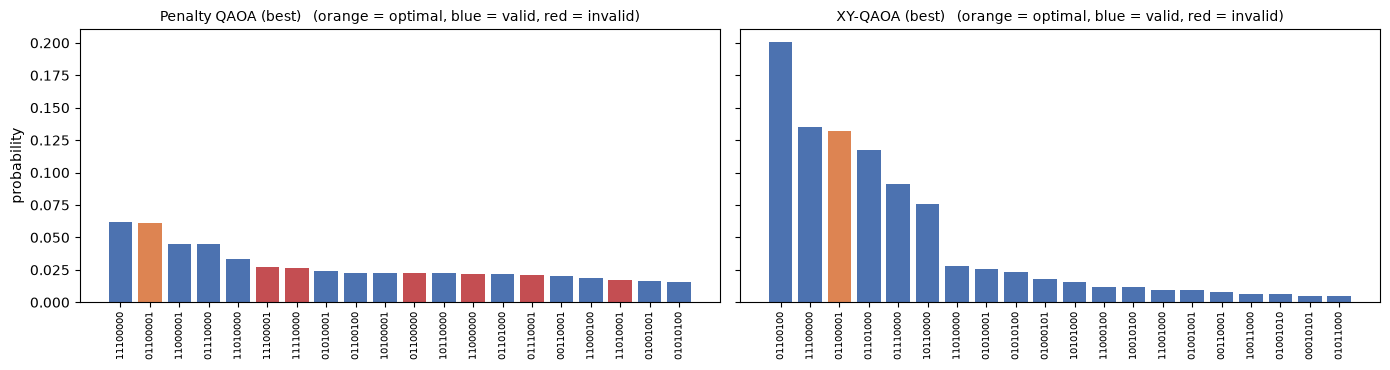

In [23]:
pool = {("CVaR", p): v for p, v in results_cvar.items()} | {("mean", p): v for p, v in results_xy.items()}
obj_name, p_xy = max(pool, key=lambda k: pool[k]["p_opt"])
r = pool[(obj_name, p_xy)]

H_xy_shift = (H_f - SparsePauliOp("I" * n, f[valid].mean())).simplify()   # constant shift = global phase
ans_xy = QAOAAnsatz(cost_operator=(H_xy_shift / r["scale"]).simplify(), reps=p_xy,
                    initial_state=dicke, mixer_operator=xy_mixer(n, ring))
ans_xy.measure_all()
counts = StatevectorSampler(seed=SEED).run([ans_xy.assign_parameters(r["params"])], shots=shots).result()[0].data.meas.get_counts()

sampled_xy = np.zeros(2**n)
for k, v in counts.items():
    sampled_xy[int(k, 2)] += v / shots

print(f"Best XY setting: objective = {obj_name}, p = {p_xy}")
print(f"Sampled   P(valid) = {sampled_xy[valid].sum():.3f}   P(optimal) = {sampled_xy[opt]:.3f}")
print(f"Predicted P(valid) = {r['p_valid']:.3f}   P(optimal) = {r['p_opt']:.3f}")
print("\nMost frequent portfolios:")
for b in np.argsort(-sampled_xy)[:6]:
    tag = f"valid, rank {rank[b]:>2}/{valid.sum()}" if valid[b] else f"INVALID ({n_picked[b]} assets)"
    print(f"  {sampled_xy[b]:6.1%}  {str(names(b)):32s} {tag}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, smp, title in [(axes[0], sampled, "Penalty QAOA (best)"), (axes[1], sampled_xy, "XY-QAOA (best)")]:
    order = np.argsort(-smp)[:20]
    ax.bar(range(len(order)), smp[order],
           color=["#dd8452" if b == opt else ("#4c72b0" if valid[b] else "#c44e52") for b in order])
    ax.set_xticks(range(len(order)), ["".join(map(str, X[b])) for b in order], rotation=90, fontsize=7)
    ax.set_title(title + "   (orange = optimal, blue = valid, red = invalid)", fontsize=10)
axes[0].set_ylabel("probability")
plt.tight_layout(); plt.savefig("figures/samples_comparison.png", dpi=150); plt.show()

## 16. Takeaways (Intermediate)

*(Numbers from the seeded run; expect small differences on another machine.)*

1. **The constraint is guaranteed:** P(valid) = **1.000** at every depth and for *any* angles. The Dicke state and the XY mixer never leave the 56 valid portfolios. Penalty QAOA reaches ≈0.62 at $\lambda_{\text{crit}}$, and up to ≈0.88 with a 10× penalty, but then quality collapses to the random level.
2. **Better answers, too:** at $p=5$, XY-QAOA finds the optimum with probability **≈13%** (~33× random, ~2× the best penalty setting) and has the highest quality (≈0.86). There is **no $\lambda$ to tune**, which removes a whole sweep.
3. **It isn't free:** the Dicke state costs a one-off **138 CX**, and each layer needs **72 CX** vs **56** for penalty QAOA. At *equal* gate budget XY still wins: **XY at $p=1$ (210 CX) ≈ penalty at $p=5$ (280 CX)** in P(optimal), with every sample valid.
4. **CVaR didn't help here, and the reason is instructive:** CVaR$_{0.1}$ only looks at the best 10% of outcomes. Once the optimum alone holds ≥10% of the probability, CVaR is already at its floor and stops pushing. CVaR pays off on *larger* problems, where P(optimal) is tiny.
5. **Classical still wins at this size:** exact enumeration takes a few milliseconds and short simulated-annealing runs find the optimum almost every time. The value here is *which encoding works*, not speed. Annealing's swap move is the classical twin of the XY mixer.
6. **Optimization is still the bottleneck:** the curves aren't perfectly monotone in $p$ (e.g. a dip at $p=4$). More restarts or better initialization would smooth them, a natural next step.

**One-line summary:** *encode the constraint in the circuit, not the cost. XY-QAOA turns "valid vs good" into "valid and better".*

**Next: Advanced (below)**
- **Trainability / barren plateaus:** measure how the gradient variance shrinks with $n$ (4 → 14 qubits) for the X mixer vs the XY mixer. Does staying inside the valid subspace (only $\binom{n}{K}$ states instead of $2^n$) help?
- **Noise:** run the best circuits on a *fake* IBM backend (`qiskit_ibm_runtime.fake_provider`) with Aer. Count the SWAPs the heavy-hex layout forces, and test dynamical decoupling and readout mitigation. Note that noise *breaks* the XY mixer's guarantee, so invalid outcomes reappear and can be filtered out (post-selection).

---
# Advanced: What Breaks When We Scale Up?

Everything so far used 8 qubits and a perfect simulator. Real utility-scale optimization faces two walls, and we can study both **on a simulator**:

- **A. Trainability (barren plateaus).** As the number of qubits grows, does the energy landscape go flat so that the optimizer has nothing to follow?
- **B. Hardware noise and connectivity.** On a real device, all-to-all $ZZ$ terms need SWAP gates, every gate adds error, and readout is imperfect. Which method survives, at which depth, and what can mitigation recover?

## A. Barren plateaus: do gradients vanish as we scale?

A **barren plateau** (McClean et al., 2018) is when the gradient of the cost, for randomly chosen angles, has a variance that shrinks **exponentially** with qubit count. The optimizer then sees a flat landscape and needs exponentially many shots to find a direction.

**Experiment.** For $n = 4, 6, \dots, 14$ assets with budget $K = n/2$, we generate random portfolio instances (same market model as before) and measure

$$
\operatorname{Var}_{\vec\theta}\!\left[\frac{\partial \langle C \rangle}{\partial \gamma_1}\right]
$$

over 100 random angle settings. We do this for the **X mixer** (penalty QAOA at $\lambda_{\text{crit}}$) and the **XY mixer** (Dicke start), at **shallow** depth ($p=2$) and **deep** depth ($p=n$). To compare fairly across sizes and methods, each cost is standardized (mean 0, std 1) over the states the circuit can reach.

Our fast simulators make this cheap: 14 qubits means a 16 384-entry state vector.

In [24]:
def random_portfolio(n_, K_, seed):
    # Same market model as Section 1, any size. Returns cost, #assets, valid mask, lambda_crit.
    r_ = np.random.default_rng(seed)
    mu_ = r_.uniform(0.04, 0.16, n_)
    F_ = r_.normal(0, 0.12, (n_, 2))
    S_ = F_ @ F_.T + np.diag(r_.uniform(0.01, 0.05, n_))
    X_ = (np.arange(2**n_)[:, None] >> np.arange(n_)) & 1
    f_ = q * np.einsum("bi,ij,bj->b", X_, S_, X_) - X_ @ mu_
    k_ = X_.sum(axis=1)
    v_ = k_ == K_
    lc = max(0.0, np.max((f_[v_].min() - f_[~v_]) / (k_[~v_] - K_) ** 2))
    return f_, k_, v_, lc


def qaoa_probs_xy_n(costs_scaled, betas, gammas, valid_n):
    # XY-QAOA from the Dicke state for any n (ring of XY gates); same maths as Section 11.
    n_ = int(np.log2(len(costs_scaled)))
    ids = np.arange(2**n_)
    pre = [(((ids >> i) & 1) != ((ids >> j) & 1), ids ^ ((1 << i) | (1 << j)))
           for i, j in [(i, (i + 1) % n_) for i in range(n_)]]
    psi = np.where(valid_n, 1 / np.sqrt(valid_n.sum()), 0).astype(complex)
    for b, g in zip(betas, gammas):
        psi = psi * np.exp(-1j * g * costs_scaled)
        for m, partner in pre:
            new = psi.copy()
            new[m] = np.cos(b) * psi[m] - 1j * np.sin(b) * psi[partner[m]]
            psi = new
    return np.abs(psi) ** 2


def grad_variance(n_, p, mixer, n_samples=100, n_instances=3, h=1e-4):
    K_ = n_ // 2
    grads = []
    for inst in range(n_instances):
        f_, k_, v_, lc = random_portfolio(n_, K_, seed=100 + inst)
        if mixer == "X":
            C_, reach = f_ + lc * (k_ - K_) ** 2, np.ones(2**n_, bool)
            sim = lambda c, x: qaoa_probs(c, x[:p], x[p:])
        else:
            C_, reach = f_.copy(), v_
            sim = lambda c, x: qaoa_probs_xy_n(c, x[:p], x[p:], v_)
        C_ = (C_ - C_[reach].mean()) / C_[reach].std()
        r_ = np.random.default_rng(inst)
        for _ in range(n_samples):
            x = r_.uniform(0, 2 * np.pi, 2 * p)
            e = np.zeros(2 * p); e[p] = h                     # d/d gamma_1 (params are [betas, gammas])
            grads.append((sim(C_, x + e) @ C_ - sim(C_, x - e) @ C_) / (2 * h))
    return np.var(grads)


sizes = [4, 6, 8, 10, 12, 14]
bp = {}
t_start = time.time()
for n_ in sizes:
    for label, p_fn in [("shallow", lambda m: 2), ("deep", lambda m: m)]:
        for mixer in ["X", "XY"]:
            bp[(n_, label, mixer)] = grad_variance(n_, p_fn(n_), mixer)
    print(f"n = {n_:2d}:  shallow X {bp[(n_,'shallow','X')]:.2e}  XY {bp[(n_,'shallow','XY')]:.2e}   |   "
          f"deep X {bp[(n_,'deep','X')]:.2e}  XY {bp[(n_,'deep','XY')]:.2e}")
print(f"Done in {time.time() - t_start:.0f} s")

n =  4:  shallow X 2.27e-01  XY 2.33e-01   |   deep X 1.66e-01  XY 3.21e-01
n =  6:  shallow X 1.90e-01  XY 8.75e-02   |   deep X 5.08e-02  XY 1.07e-01
n =  8:  shallow X 1.69e-01  XY 3.34e-02   |   deep X 1.72e-02  XY 2.71e-02
n = 10:  shallow X 2.66e-01  XY 2.43e-02   |   deep X 7.34e-03  XY 6.63e-03
n = 12:  shallow X 2.85e-01  XY 1.59e-02   |   deep X 3.94e-03  XY 2.14e-03
n = 14:  shallow X 4.40e-01  XY 1.82e-02   |   deep X 1.27e-03  XY 7.19e-04
Done in 194 s


X mixer (penalty), p = n        : variance shrinks by ~1.60x per extra qubit
XY mixer (Dicke), p = n         : variance shrinks by ~1.87x per extra qubit


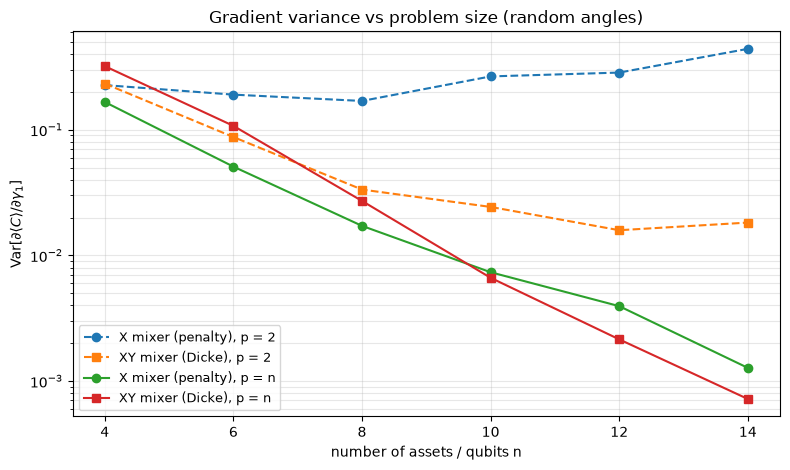

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.8))
styles = {("shallow", "X"): "o--", ("shallow", "XY"): "s--", ("deep", "X"): "o-", ("deep", "XY"): "s-"}
for (label, mixer), st in styles.items():
    v = np.array([bp[(n_, label, mixer)] for n_ in sizes])
    name = f"{'X mixer (penalty)' if mixer == 'X' else 'XY mixer (Dicke)'}, {'p = 2' if label == 'shallow' else 'p = n'}"
    ax.semilogy(sizes, v, st, label=name)
    if label == "deep":   # fit Var ~ b^(-n)
        slope = np.polyfit(sizes, np.log2(v), 1)[0]
        print(f"{name:32s}: variance shrinks by ~{2**-slope:.2f}x per extra qubit")
ax.set_xlabel("number of assets / qubits n"); ax.set_ylabel(r"Var[$\partial\langle C\rangle / \partial\gamma_1$]")
ax.set_title("Gradient variance vs problem size (random angles)")
ax.set_xticks(sizes); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig("figures/barren_plateaus.png", dpi=150); plt.show()

**Reading the plot.** Deep circuits ($p = n$) of both kinds show **exponentially vanishing gradients**, the barren-plateau signature. The XY mixer does *not* escape it. Restricting to valid portfolios shrinks the search space from $2^n$ to $\binom{n}{n/2}$, but that is *still exponential* in $n$, which matches the theory that plateaus are governed by the dimension of the space the circuit explores (Larocca et al., 2022; Ragone et al., 2024). Shallow circuits keep usable gradients (the shallow XY curve flattens out around $10^{-2}$; the shallow penalty curve even grows, but mostly because its standardized cost is dominated by the penalty, so those gradients mostly push toward *valid*, not *good*). This is why the **smart initialization** (ramp + INTERP) from the Beginner section matters: start in a good region rather than at random.

## B. Noise: running on a (simulated) IBM Heron device

We use `FakeFez`, a snapshot of a real 156-qubit IBM **Heron** processor: its heavy-hex connectivity, native gates (CZ, $\sqrt{X}$, $R_Z$) and **measured error rates**. `AerSimulator.from_backend` turns that into a noise model, so this is about as close to hardware as a laptop gets.

Plan:
1. **Transpile** the optimized circuits (penalty and XY, $p = 1 \dots 5$) to the device and count the two-qubit gates the routing adds.
2. **Run with noise** using the angles optimized on the ideal simulator ("train ideal, deploy noisy").
3. **Mitigate** with two cheap, explainable techniques:
   - **Readout mitigation:** measure how often each qubit's 0/1 gets flipped (2 calibration circuits), then invert that error on the results.
   - **Post-selection:** throw away samples with the wrong number of assets. This is legitimate for both methods, but it matters most for XY-QAOA: its *ideal* output is always valid, so every invalid sample is a **detected error**.

In [26]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez

backend = FakeFez()
noisy_sim = AerSimulator.from_backend(backend)
print(f"Backend: {backend.name}, {backend.num_qubits} qubits, native gates: "
      f"{sorted(g for g in backend.operation_names if g in ('cz', 'sx', 'rz', 'x', 'ecr', 'cx'))}")


def penalty_circuit(p):
    r_ = results[(1.0, p)]
    Hp, cp = portfolio_problem(lam_crit)
    Hs = (Hp - SparsePauliOp("I" * n, cp.mean())).simplify()
    a = QAOAAnsatz((Hs / r_["scale"]).simplify(), reps=p)
    a.measure_all()
    return a.assign_parameters(r_["params"])


def xy_circuit(p):
    r_ = results_xy[p]
    Hs = (H_f - SparsePauliOp("I" * n, f[valid].mean())).simplify()
    a = QAOAAnsatz((Hs / r_["scale"]).simplify(), reps=p, initial_state=dicke, mixer_operator=xy_mixer(n, ring))
    a.measure_all()
    return a.assign_parameters(r_["params"])


def two_q(qc):
    ops = qc.count_ops()
    return sum(ops.get(g, 0) for g in ("cz", "cx", "ecr"))


compiled = {}
print(f"\n{'':10s}{'all-to-all CX':>15s}{'on device (CZ)':>16s}{'device depth':>14s}")
for method, build in [("penalty", penalty_circuit), ("XY", xy_circuit)]:
    for p in depths:
        qc = build(p)
        ideal_2q = two_q(transpile(qc, basis_gates=["cx", "u"], optimization_level=1))
        tqc = transpile(qc, backend, optimization_level=3, seed_transpiler=SEED)
        compiled[(method, p)] = tqc
        print(f"{method:>7s} p={p}{ideal_2q:15d}{two_q(tqc):16d}{tqc.depth():14d}")

Backend: fake_fez, 156 qubits, native gates: ['cz', 'rz', 'sx', 'x']

            all-to-all CX  on device (CZ)  device depth
penalty p=1             56              92           197
penalty p=2            112             203           352
penalty p=3            168             315           590
penalty p=4            224             442           834
penalty p=5            280             538           946
     XY p=1            210             345           808
     XY p=2            282             511          1084
     XY p=3            354             680          1427
     XY p=4            426             810          1729
     XY p=5            498             985          2062


In [27]:
def readout_calibration(tqc, shots=8192):
    # Per-qubit readout flip rates on the physical qubits this circuit is measured on.
    phys = tqc.layout.final_index_layout()[:n]          # physical qubit holding each logical qubit
    probs01 = []
    for prep in (0, 1):
        cal = QuantumCircuit(n, n)
        if prep:
            cal.x(range(n))
        cal.measure(range(n), range(n))
        tcal = transpile(cal, backend, initial_layout=phys, optimization_level=0)
        cnt = noisy_sim.run(tcal, shots=shots, seed_simulator=SEED).result().get_counts()
        ones = np.zeros(n)
        for k, v in cnt.items():
            ones += np.array([int(c) for c in k[::-1]]) * v
        probs01.append(ones / shots)                    # P(read 1 | prepared prep), per qubit
    p1_0, p1_1 = probs01
    return [np.array([[1 - p1_0[i], 1 - p1_1[i]], [p1_0[i], p1_1[i]]]) for i in range(n)]


def mitigate_readout(probs, mats):
    # Apply the inverse of the tensored assignment matrix, then project back to a distribution.
    t = probs.reshape([2] * n)
    for i, A in enumerate(mats):
        ax = n - 1 - i                                  # qubit i = bit i = axis n-1-i in C order
        t = np.moveaxis(np.tensordot(np.linalg.inv(A), t, axes=([1], [ax])), 0, ax)
    v = np.clip(t.reshape(-1), 0, None)
    return v / v.sum()


def counts_to_probs(counts):
    v = np.zeros(2**n)
    for k, c in counts.items():
        v[int(k, 2)] += c
    return v / v.sum()


noisy = {}
t_start = time.time()
for (method, p), tqc in compiled.items():
    raw = counts_to_probs(noisy_sim.run(tqc, shots=shots, seed_simulator=SEED).result().get_counts())
    mit = mitigate_readout(raw, readout_calibration(tqc))
    noisy[(method, p)] = dict(raw=metrics(raw), mit=metrics(mit))
print(f"Noisy runs done in {time.time() - t_start:.0f} s\n")

ideal = {("penalty", p): results[(1.0, p)] for p in depths} | {("XY", p): results_xy[p] for p in depths}
print(f"{'':12s}{'P(valid)':>26s}   {'P(opt | valid)  [after post-selection]':>44s}")
print(f"{'':12s}{'ideal':>8s}{'noisy':>9s}{'+ro mit':>9s}   {'ideal':>14s}{'noisy':>9s}{'+ro mit':>9s}")
for (method, p) in compiled:
    i_, r_, m_ = ideal[(method, p)], noisy[(method, p)]["raw"], noisy[(method, p)]["mit"]
    ps = lambda d: d["p_opt"] / d["p_valid"]
    print(f"{method:>7s} p={p}{i_['p_valid']:8.3f}{r_['p_valid']:9.3f}{m_['p_valid']:9.3f}   "
          f"{ps(i_):14.3f}{ps(r_):9.3f}{ps(m_):9.3f}")

Noisy runs done in 70 s

                              P(valid)         P(opt | valid)  [after post-selection]
               ideal    noisy  +ro mit            ideal    noisy  +ro mit
penalty p=1   0.477    0.425    0.435            0.027    0.034    0.035
penalty p=2   0.609    0.448    0.463            0.047    0.042    0.042
penalty p=3   0.530    0.426    0.434            0.063    0.050    0.051
penalty p=4   0.531    0.358    0.363            0.057    0.038    0.038
penalty p=5   0.619    0.394    0.402            0.097    0.052    0.053
     XY p=1   1.000    0.470    0.483            0.056    0.044    0.045
     XY p=2   1.000    0.383    0.390            0.084    0.053    0.054
     XY p=3   1.000    0.328    0.334            0.100    0.045    0.046
     XY p=4   1.000    0.302    0.304            0.086    0.029    0.029
     XY p=5   1.000    0.285    0.287            0.130    0.030    0.030


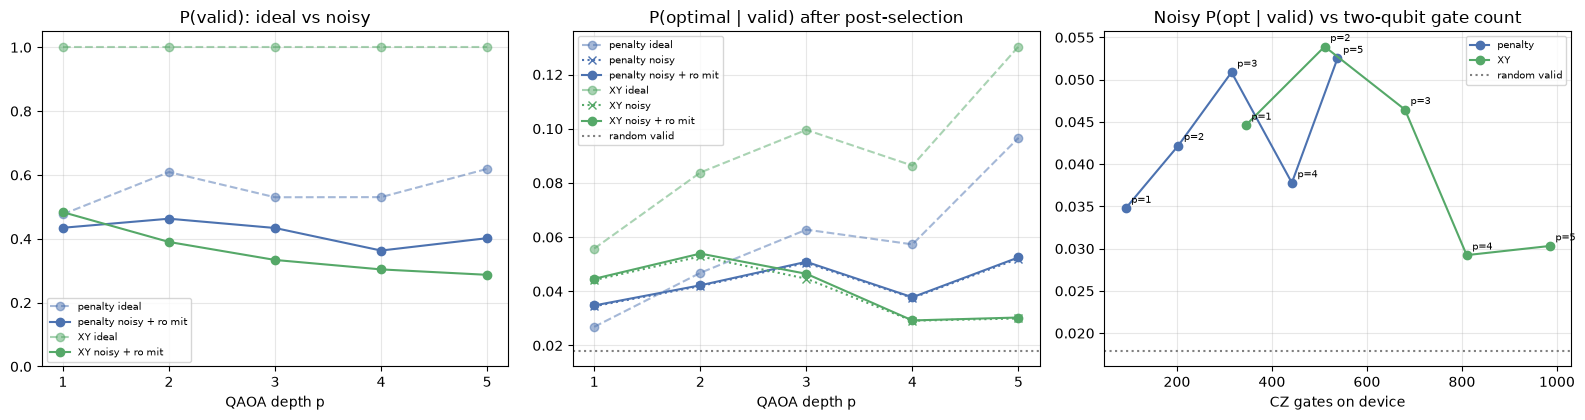

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cols = {"penalty": "#4c72b0", "XY": "#55a868"}
for method in ["penalty", "XY"]:
    c = cols[method]
    ps = lambda d: d["p_opt"] / d["p_valid"]
    axes[0].plot(depths, [ideal[(method, p)]["p_valid"] for p in depths], "o--", color=c, alpha=0.5, label=f"{method} ideal")
    axes[0].plot(depths, [noisy[(method, p)]["mit"]["p_valid"] for p in depths], "o-", color=c, label=f"{method} noisy + ro mit")
    axes[1].plot(depths, [ps(ideal[(method, p)]) for p in depths], "o--", color=c, alpha=0.5, label=f"{method} ideal")
    axes[1].plot(depths, [ps(noisy[(method, p)]["raw"]) for p in depths], "x:", color=c, label=f"{method} noisy")
    axes[1].plot(depths, [ps(noisy[(method, p)]["mit"]) for p in depths], "o-", color=c, label=f"{method} noisy + ro mit")
    axes[2].plot([two_q(compiled[(method, p)]) for p in depths],
                 [ps(noisy[(method, p)]["mit"]) for p in depths], "o-", color=c, label=method)
    for p in depths:
        axes[2].annotate(f"p={p}", (two_q(compiled[(method, p)]), ps(noisy[(method, p)]["mit"])),
                         xytext=(4, 4), textcoords="offset points", fontsize=7)
for ax in axes[:2]:
    ax.set_xlabel("QAOA depth p"); ax.set_xticks(depths)
axes[1].axhline(1 / valid.sum(), ls=":", color="gray", label="random valid")
axes[2].axhline(1 / valid.sum(), ls=":", color="gray", label="random valid")
axes[0].set_title("P(valid): ideal vs noisy"); axes[0].set_ylim(0, 1.05)
axes[1].set_title("P(optimal | valid) after post-selection")
axes[2].set_title("Noisy P(opt | valid) vs two-qubit gate count"); axes[2].set_xlabel("CZ gates on device")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/noise.png", dpi=150); plt.show()

## Takeaways (Advanced)

**A. Trainability**
1. **Deep circuits hit a barren plateau, with either mixer.** At $p = n$, gradient variance shrinks ~**1.6×** (X) and ~**1.9×** (XY) per extra qubit, so at 50 qubits it would be ~$10^{-10}$ smaller than at 8.
2. **Constraint-preserving ≠ plateau-free.** The valid subspace $\binom{n}{n/2}$ still grows exponentially, so the XY mixer decays just as fast.
3. **Shallow circuits + smart initialization** (ramp/INTERP, warm starts, parameter transfer) are the practical way forward, not "just add layers".

**B. Noise on a simulated IBM Heron device**
4. **Connectivity roughly doubles the cost:** routing onto heavy-hex takes penalty QAOA from 56 → 92 two-qubit gates at $p=1$ and XY-QAOA from 210 → 345 (≈1000 at $p=5$).
5. **Noise erases XY's guarantee:** P(valid) drops from **1.00 → 0.47** at $p=1$ and **0.28** at $p=5$. Every invalid sample is a *detected* error, so post-selection removes them, at the cost of throwing away up to ~70% of the shots.
6. **The ideal-simulator winner is not the hardware winner.** After post-selection, the best noisy results are a **tie** (~5.3% optimal, ~3× random): penalty QAOA at $p=5$ vs XY-QAOA at just $p=2$. Deeper XY circuits get *worse* under noise (13% ideal → 3% noisy at $p=5$). **On hardware, the currency is two-qubit gates, not layers.**
7. **Readout mitigation barely moves the needle** (≤1 percentage point): gate errors dominate at these depths, so effort is better spent on reducing the gate count.

**One-line summary:** *the clever circuit wins on paper, but on hardware it has to earn its extra gates. The next step is to make XY-QAOA hardware-native.*

**What we did *not* do (and why)**
- **Dynamical decoupling / twirling:** these mainly fight *coherent* errors and crosstalk, which Aer's backend noise model barely includes. A simulator would under-sell them, so testing them properly needs real hardware.
- **Bigger instances under noise:** we kept $n = 8$ so that brute force still certifies the answer. Next steps: (i) a **hardware-native XY ring** that follows a chain of physically connected qubits, so the mixer needs no SWAPs; (ii) a **cheaper Dicke-state preparation** (or starting from a single good valid portfolio, *warm start*), which removes most of the 138-CX overhead; (iii) choosing $p$ **by the noise budget**, not by the ideal simulator.

---
# Appendix: Independent cross-check (5 assets, separate implementation)

*Implementation by Shikha (team member), cleaned up for inclusion here.*

**Why this appendix?** A second implementation, written separately and run on a **different problem instance**, is an independent check of the main results. It shares no code with the sections above: circuits are written gate by gate (no `QAOAAnsatz`), and probabilities come from Qiskit's `Statevector` directly (no fast simulator).

| | Main notebook | This appendix |
|---|---|---|
| Instance | 8 assets, pick 3 (56 valid of 256) | **5 assets, pick 3 (10 valid of 32)** |
| Covariance | 2-factor model, risk aversion 1.0 | 3-factor model, risk aversion 1.3 |
| Cost layer | `QAOAAnsatz` | hand-built `rz` + `rzz` gates |
| XY mixer | `XXPlusYYGate` ring | `rxx` + `ryy` ring |
| Fixed-K start | Bärtschi–Eidenbenz Dicke circuit | `initialize` (a simulator shortcut, not a hardware-ready circuit) |
| Penalty | in units of $\lambda_{crit}$ | absolute values 0.3, 1, 3 |

Variables that would clash with the main notebook carry the suffix `_A`.

In [29]:
import pandas as pd   # on qBraid: %pip install pandas  (if missing)

SEED_A = 42
N = 5                  # number of assets / qubits
K_A = 3                # must select exactly 3 assets
RISK_AVERSION = 1.3

assets = [f"Asset {i}" for i in range(N)]
returns = np.array([0.15, 0.21, 0.12, 0.18, 0.16])
exposures = np.array([
    [0.12, 0.04, 0.00],
    [0.18, 0.02, 0.04],
    [0.04, 0.13, 0.03],
    [0.10, 0.09, 0.02],
    [0.03, 0.06, 0.15],
])
covariance = exposures @ exposures.T   # PSD by construction

assert covariance.shape == (N, N)
assert np.all(np.linalg.eigvalsh(covariance) >= -1e-10)
assert 0 < K_A < N
print("Expected returns:", returns)
print("Covariance matrix:\n", np.round(covariance, 4))

Expected returns: [0.15 0.21 0.12 0.18 0.16]
Covariance matrix:
 [[0.016  0.0224 0.01   0.0156 0.006 ]
 [0.0224 0.0344 0.011  0.0206 0.0126]
 [0.01   0.011  0.0194 0.0163 0.0135]
 [0.0156 0.0206 0.0163 0.0185 0.0114]
 [0.006  0.0126 0.0135 0.0114 0.027 ]]


In [30]:
def portfolio_cost(bits):
    x = np.asarray(bits, dtype=float)
    return float(-returns @ x + RISK_AVERSION * (x @ covariance @ x))

# Qiskit little-endian: integer's bit i corresponds to qubit/asset i.
def integer_to_bits(number, n=N):
    return np.array([(number >> i) & 1 for i in range(n)], dtype=int)

all_bits = np.array([integer_to_bits(i) for i in range(2**N)])
raw_costs = np.array([portfolio_cost(x) for x in all_bits])
feasible = (all_bits.sum(axis=1) == K_A)
optimal_value = float(raw_costs[feasible].min())
optimal_ids = np.flatnonzero(feasible & np.isclose(raw_costs, optimal_value, atol=1e-10))

print(f"Feasible portfolios: {feasible.sum()} out of {2**N}")
print(f"Exact optimal cost: {optimal_value:.6f}")
for j in optimal_ids:
    print("Optimal selection:", [assets[i] for i in np.flatnonzero(all_bits[j])])
print(f"Random valid portfolio: cost gap {raw_costs[feasible].mean() - optimal_value:.4f}, "
      f"P(optimal) = {1 / feasible.sum():.2f}")

Feasible portfolios: 10 out of 32
Exact optimal cost: -0.330170
Optimal selection: ['Asset 1', 'Asset 3', 'Asset 4']
Random valid portfolio: cost gap 0.0368, P(optimal) = 0.10


### Encoding check

The QUBO $f(\vec x) + A\,(\sum_i x_i - K)^2$ is expanded into Ising $Z$ / $ZZ$ coefficients by hand and verified on all 32 bitstrings for three penalty values. We also compute this instance's $\lambda_{crit}$ (Section 3 of the main notebook) to see where the chosen penalties sit.

In [31]:
def make_ising(penalty=0.0):
    # Return Z and ZZ coefficients for f(x) + penalty*(sum(x)-K)^2.
    linear = -returns + RISK_AVERSION * np.diag(covariance) + penalty * (1 - 2*K_A)
    pair = np.zeros((N, N))
    for i in range(N):
        for j in range(i+1, N):
            pair[i, j] = 2 * RISK_AVERSION * covariance[i, j] + 2 * penalty
    h = -0.5 * linear.copy()
    J = np.zeros((N, N))
    for i in range(N):
        for j in range(i+1, N):
            h[i] -= pair[i, j] / 4
            h[j] -= pair[i, j] / 4
            J[i, j] = pair[i, j] / 4
    offset = penalty * K_A**2 + 0.5 * linear.sum() + 0.25 * np.triu(pair, 1).sum()
    return h, J, offset

# Verify the expansion on all 2**N bitstrings.
for penalty in (0.0, 0.4, 2.0):
    h, J, offset = make_ising(penalty)
    for bits in all_bits:
        z = 1 - 2 * bits
        energy = offset + h @ z + sum(J[i, j]*z[i]*z[j] for i in range(N) for j in range(i+1, N))
        expected = portfolio_cost(bits) + penalty * (int(bits.sum())-K_A)**2
        assert np.isclose(energy, expected)
print("All QUBO-to-Ising checks passed")

k_all = all_bits.sum(axis=1)
lam_crit_A = max(0.0, np.max((optimal_value - raw_costs[~feasible]) / (k_all[~feasible] - K_A) ** 2))
print(f"lambda_crit for this instance = {lam_crit_A:.4f}  ->  penalties 0.3 / 1 / 3 are "
      f"{0.3/lam_crit_A:.0f}x / {1/lam_crit_A:.0f}x / {3/lam_crit_A:.0f}x lambda_crit")

All QUBO-to-Ising checks passed
lambda_crit for this instance = 0.0148  ->  penalties 0.3 / 1 / 3 are 20x / 68x / 203x lambda_crit


### Circuits, built gate by gate

- **Baseline (penalty X-QAOA):** Hadamards, then per layer `rz` / `rzz` cost gates and `rx` mixer gates.
- **Fixed-K XY-QAOA:** start in the uniform superposition of all $K$-asset portfolios, then use the cost **without penalty** and a ring of `rxx` + `ryy` gates. These commute on each pair and preserve the number of selected assets.

In [32]:
def uniform_fixed_k_state(n=N, k=K_A):
    state = np.zeros(2**n, dtype=complex)
    choices = [v for v in range(2**n) if v.bit_count() == k]
    state[choices] = 1/np.sqrt(len(choices))
    return state


def qaoa_circuit(gammas, betas, penalty=0.0, improved=False):
    assert len(gammas) == len(betas)
    circuit = QuantumCircuit(N)
    if improved:
        circuit.initialize(uniform_fixed_k_state(), range(N))
    else:
        circuit.h(range(N))
    h, J, _ = make_ising(0.0 if improved else penalty)
    for gamma, beta in zip(gammas, betas):
        for i in range(N):
            if abs(h[i]) > 1e-12:
                circuit.rz(2 * gamma * h[i], i)
        for i in range(N):
            for j in range(i+1, N):
                if abs(J[i, j]) > 1e-12:
                    circuit.rzz(2 * gamma * J[i, j], i, j)
        if improved:
            # Connected ring; RXX and RYY commute on each pair, preserving Hamming weight.
            ring_A = [(i, (i+1) % N) for i in range(N)]
            for i, j in ring_A:
                circuit.rxx(2 * beta, i, j)
                circuit.ryy(2 * beta, i, j)
        else:
            for i in range(N):
                circuit.rx(2 * beta, i)
    return circuit

print("Baseline gates:", qaoa_circuit([0.2], [0.3], penalty=1.0).size())
print("XY-QAOA gates:", qaoa_circuit([0.2], [0.3], improved=True).size())

Baseline gates: 25
XY-QAOA gates: 26


### Training

COBYLA minimizes the expected cost (with the penalty for the baseline, without it for XY), using several random restarts. Each deeper circuit is warm-started from the previous depth's angles, with a small new layer (angle 0.05) appended.

In [33]:
def probabilities(params, p, penalty=0.0, improved=False):
    gammas, betas = params[:p], params[p:]
    circuit = qaoa_circuit(gammas, betas, penalty=penalty, improved=improved)
    return Statevector.from_instruction(circuit).probabilities()


def expected_training_cost(params, p, penalty=0.0, improved=False):
    probs_ = probabilities(params, p, penalty, improved)
    energies = raw_costs if improved else raw_costs + penalty * (all_bits.sum(axis=1)-K_A)**2
    return float(probs_ @ energies)


def train_qaoa(p, penalty=0.0, improved=False, restarts=4, maxiter=160, previous=None, seed=SEED_A):
    local_rng = np.random.default_rng(seed)
    initial_points = [local_rng.uniform(-np.pi, np.pi, 2*p) for _ in range(restarts)]
    if previous is not None and p > 1:
        prev_ = np.asarray(previous)
        init = np.r_[prev_[:p-1], 0.05, prev_[p-1:], 0.05]   # [gammas..., new gamma, betas..., new beta]
        initial_points.insert(0, init)

    best_ = None
    for x0 in initial_points:
        res_ = minimize(expected_training_cost, x0,
                        args=(p, penalty, improved),
                        method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.5})
        if best_ is None or res_.fun < best_.fun:
            best_ = res_
    return best_

print("Objective sanity check:", expected_training_cost(np.array([0.1, 0.2]), 1, 2.0))

Objective sanity check: 4.689435282090869


In [34]:
DEPTHS = [1, 2, 3]
PENALTIES = [0.3, 1.0, 3.0]
RESTARTS = 3
MAXITER = 120
SHOTS = 2048

runs = []
t_start = time.time()
for penalty in PENALTIES:
    prev_ = None
    for p in DEPTHS:
        res_ = train_qaoa(p, penalty=penalty, restarts=RESTARTS,
                          maxiter=MAXITER, previous=prev_, seed=SEED_A + int(10*penalty) + p)
        runs.append({"method": "Penalty X-QAOA", "depth": p, "penalty": penalty,
                     "params": res_.x, "train_energy": res_.fun})
        prev_ = res_.x
    print(f"Finished baseline penalty={penalty}")

prev_ = None
for p in DEPTHS:
    res_ = train_qaoa(p, improved=True, restarts=RESTARTS,
                      maxiter=MAXITER, previous=prev_, seed=SEED_A + 100 + p)
    runs.append({"method": "Fixed-K XY-QAOA", "depth": p, "penalty": 0.0,
                 "params": res_.x, "train_energy": res_.fun})
    prev_ = res_.x
print(f"Finished {len(runs)} conditions in {time.time() - t_start:.0f} s")

Finished baseline penalty=0.3
Finished baseline penalty=1.0
Finished baseline penalty=3.0
Finished 12 conditions in 17 s


In [35]:
def evaluate_run(run, shots=SHOTS):
    p = run["depth"]
    improved = run["method"] == "Fixed-K XY-QAOA"
    probs_ = probabilities(run["params"], p, run["penalty"], improved)
    feasible_prob = float(probs_[feasible].sum())
    optimal_prob = float(probs_[optimal_ids].sum())
    conditional_cost = float(probs_[feasible] @ raw_costs[feasible] / feasible_prob) if feasible_prob > 1e-12 else np.nan
    # Fixed seed for reproducible measurements; per-run seed changes with method and parameters.
    sample_rng = np.random.default_rng(SEED_A + p + int(run["penalty"]*100) + (10000 if improved else 0))
    measured = sample_rng.choice(2**N, size=shots, p=probs_)
    sampled_feasible = measured[feasible[measured]]
    best_sampled = float(raw_costs[sampled_feasible].min()) if len(sampled_feasible) else np.nan
    return {"method": run["method"], "depth": p, "penalty": run["penalty"],
            "feasible_probability": feasible_prob, "optimal_probability": optimal_prob,
            "conditional_expected_cost": conditional_cost,
            "conditional_gap": conditional_cost - optimal_value,
            "best_feasible_sampled_gap": best_sampled - optimal_value if np.isfinite(best_sampled) else np.nan}

results_A = pd.DataFrame([evaluate_run(run) for run in runs])
print("Exact optimum:", round(optimal_value, 6))
display(results_A.round(4))
assert np.all(results_A["feasible_probability"].between(-1e-9, 1 + 1e-9))
assert np.all(results_A["conditional_gap"].dropna() > -1e-8)
xy_results = results_A[results_A.method == "Fixed-K XY-QAOA"]
assert np.allclose(xy_results.feasible_probability, 1.0, atol=1e-9)
print("All XY runs preserve exact K in ideal simulation")
results_A.to_csv("results/appendix_crosscheck.csv", index=False)

Exact optimum: -0.33017


,method,depth,penalty,feasible_probability,optimal_probability,conditional_expected_cost,conditional_gap,best_feasible_sampled_gap
0,Penalty X-QAOA,1,0.3,0.6575,0.0676,-0.2937,0.0365,0.0
1,Penalty X-QAOA,2,0.3,0.6717,0.0689,-0.2937,0.0365,0.0
2,Penalty X-QAOA,3,0.3,0.7292,0.0766,-0.2940,0.0362,0.0
3,Penalty X-QAOA,1,1.0,0.6562,0.0662,-0.2934,0.0367,0.0
4,Penalty X-QAOA,2,1.0,0.7626,0.0951,-0.2962,0.0340,0.0
5,Penalty X-QAOA,3,1.0,0.8880,0.0865,-0.2931,0.0371,0.0
6,Penalty X-QAOA,1,3.0,0.6481,0.0621,-0.2928,0.0374,0.0
7,Penalty X-QAOA,2,3.0,0.6956,0.0660,-0.2927,0.0375,0.0
8,Penalty X-QAOA,3,3.0,0.9320,0.0922,-0.2932,0.0370,0.0
9,Fixed-K XY-QAOA,1,0.0,1.0000,0.3555,-0.2996,0.0305,0.0


All XY runs preserve exact K in ideal simulation


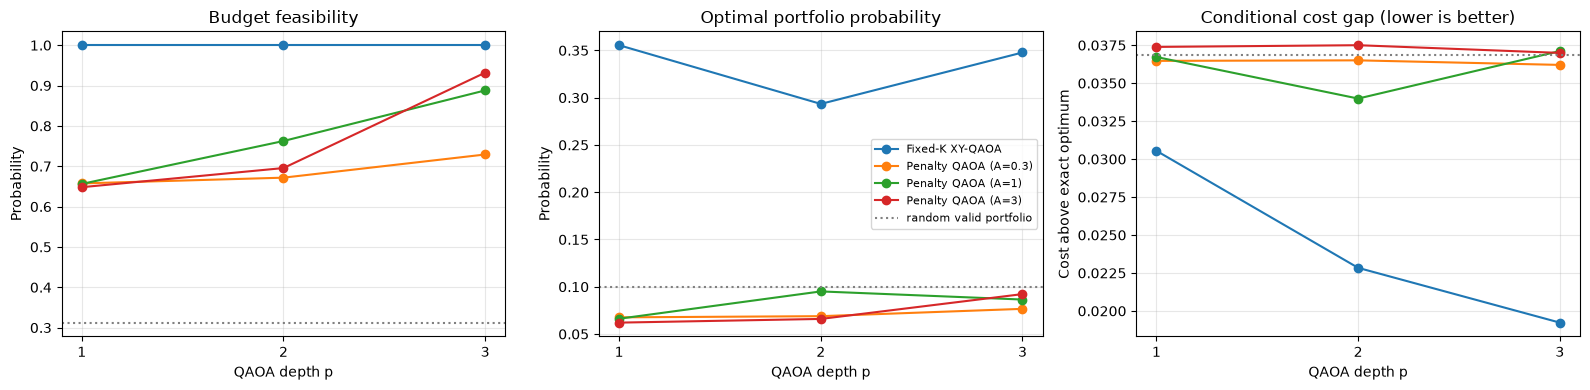

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (method, penalty), group in results_A.groupby(["method", "penalty"], sort=True):
    name = method if method == "Fixed-K XY-QAOA" else f"Penalty QAOA (A={penalty:g})"
    group = group.sort_values("depth")
    for ax, col in zip(axes, ["feasible_probability", "optimal_probability", "conditional_gap"]):
        ax.plot(group.depth, group[col], marker="o", label=name)
# Random-guess references
axes[0].axhline(feasible.mean(), ls=":", color="gray", label="random bitstring")
axes[1].axhline(1 / feasible.sum(), ls=":", color="gray", label="random valid portfolio")
axes[2].axhline(raw_costs[feasible].mean() - optimal_value, ls=":", color="gray", label="random valid portfolio")
for ax, title, ylabel in zip(axes,
    ["Budget feasibility", "Optimal portfolio probability", "Conditional cost gap (lower is better)"],
    ["Probability", "Probability", "Cost above exact optimum"]):
    ax.set_title(title); ax.set_xlabel("QAOA depth p"); ax.set_ylabel(ylabel)
    ax.set_xticks(DEPTHS); ax.grid(alpha=0.3)
axes[1].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig("figures/appendix_crosscheck.png", dpi=150)
plt.show()

In [37]:
xy_idx = results_A[results_A.method == "Fixed-K XY-QAOA"].optimal_probability.idxmax()
xy_row = results_A.loc[xy_idx]
chosen = next(r for r in runs if r["method"] == "Fixed-K XY-QAOA" and r["depth"] == xy_row.depth)
probs_A = probabilities(chosen["params"], chosen["depth"], improved=True)
print("Chosen depth:", chosen["depth"])
print("Probability of optimum:", round(float(probs_A[optimal_ids].sum()), 4))
for index in np.argsort(probs_A)[::-1][:6]:
    bits = integer_to_bits(int(index))
    if probs_A[index] > 1e-7:
        print(f"P={probs_A[index]:.3f} | {[assets[i] for i in np.flatnonzero(bits)]} | cost={raw_costs[index]:.5f}")

Chosen depth: 1
Probability of optimum: 0.3555
P=0.355 | ['Asset 1', 'Asset 3', 'Asset 4'] | cost=-0.33017
P=0.239 | ['Asset 2', 'Asset 3', 'Asset 4'] | cost=-0.26851
P=0.151 | ['Asset 1', 'Asset 2', 'Asset 4'] | cost=-0.28850
P=0.079 | ['Asset 0', 'Asset 1', 'Asset 4'] | cost=-0.31278
P=0.048 | ['Asset 0', 'Asset 2', 'Asset 4'] | cost=-0.27218
P=0.042 | ['Asset 1', 'Asset 2', 'Asset 3'] | cost=-0.29147


### Appendix results: what the cross-check shows

*(Numbers from a top-to-bottom run; seeded and deterministic.)*

1. **Same main finding, different instance and code:** every XY-QAOA run is 100% valid by construction, and penalty QAOA reaches only ≈65–93% valid.
2. **The penalty learned "be valid", not "be good".** All penalties used (0.3, 1, 3) are **20–200× $\lambda_{crit}$** (0.015) for this instance. Exactly as in the main notebook's heatmaps, a penalty this strong drowns out the return/risk signal: penalty-QAOA's cost gap among valid samples (≈0.034–0.037) is essentially that of a **random valid portfolio** (0.037).
3. **XY-QAOA learns quality:** P(optimal) ≈ **0.29–0.36**, i.e. **3–3.5× a random valid portfolio** and ~4× the best penalty run, and its cost gap shrinks steadily with depth (0.031 → 0.023 → 0.019).
4. **What did not work, part 1 (optimization):** P(optimal) is not monotone in depth (it dips at $p=2$). With only 3 random restarts and 120 COBYLA iterations, the optimizer does not always find the best angles. The main notebook uses ramp + INTERP initialization for this reason.
5. **What did not work, part 2 (reproducibility):** the first version of this notebook was run **out of order**, and its saved outputs disagreed with the code (e.g. XY at $p=3$ looked *worse than random*). Re-running top to bottom gives the table above. Lesson: always *Restart & Run All* before trusting the numbers.
6. **"Best sample found" is uninformative here:** with 32 bitstrings and 2048 shots, every run's best feasible sample is optimal (gap 0), whether or not the run was good. This is why the main notebook reports probabilities instead.

---
## Credits, references and AI usage

**Built on:** B. Tirado, *Combinatorial Optimization with QAOA: Max-Cut*, tutorial notebook, BasQ Qiskit Fall Fest, 2026 (text CC BY 4.0, code Apache 2.0).

**Appendix:** independent implementation by team member Shikha; cleaned up and integrated with Claude's help.

**References**
- H. Markowitz, *Portfolio Selection*, J. Finance (1952). The mean–variance model.
- E. Farhi, J. Goldstone, S. Gutmann, *A Quantum Approximate Optimization Algorithm*, arXiv:1411.4028 (2014).
- S. Hadfield et al., *From the QAOA to the Quantum Alternating Operator Ansatz*, Algorithms 12, 34 (2019). XY mixers.
- A. Bärtschi, S. Eidenbenz, *Deterministic Preparation of Dicke States*, FCT (2019).
- L. Zhou et al., *Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices*, PRX 10, 021067 (2020). INTERP initialization.
- P. Barkoutsos et al., *Improving Variational Quantum Optimization using CVaR*, Quantum 4, 256 (2020).
- J. McClean et al., *Barren plateaus in quantum neural network training landscapes*, Nat. Commun. 9, 4812 (2018).
- M. Larocca et al., *Diagnosing Barren Plateaus*, Quantum 6, 824 (2022); M. Ragone et al., *A Lie algebraic theory of barren plateaus*, Nat. Commun. 15, 7172 (2024).

**AI usage.** This project was developed with substantial help from Claude (Anthropic), an AI assistant, used through Claude Code. Claude wrote most of the code and explanatory text and ran local tests, working under the team's direction. The team chose the challenge and the Beginner → Intermediate → Advanced route, ran and checked the notebook on qBraid, reviewed the results, and *[team: add your own contributions here]*. The full statement is in the written report.